# Báo cáo chất lượng dữ liệu Yelp thô

## 0. Mục đích và phạm vi

**Khảo sát một lần trên dữ liệu Yelp *thô*, snapshot xuất ngày 2022-01-19**, phục vụ bài toán gợi ý POI kế tiếp (ST-GUGEN). Báo cáo trả lời hai câu hỏi:

1. **Dữ liệu thô đang có lỗi gì, ở bảng nào, nặng đến đâu** theo 6 khía cạnh của báo cáo đo lường CLDL (Đầy đủ, Duy nhất, Nhất quán, Kịp thời, Hợp lệ, Chính xác).
2. **Mỗi lỗi nên xử lý thế nào** trước khi tiền xử lý thành chuỗi ghé thăm: dùng trực tiếp, gắn cờ, sửa/điền, hay loại.

**Không thuộc phạm vi:** giám sát liên tục/tự động; đo lại sau làm sạch; đo ảnh hưởng của chất lượng dữ liệu lên độ chính xác mô hình (AccTEMPO); kiểm tra dữ liệu có đúng với thực tế ngoài đời hay không (khía cạnh *Chính xác* chỉ kiểm tra đối chiếu nội bộ giữa các bảng/cột).


## 1. Cách đo

**Đơn vị đo là ô.** Mỗi quy tắc kiểm tra từng ô và trả về **True** (đạt), **False** (vi phạm) hoặc **N/A** (không xét, không tính vào tử số lẫn mẫu số).

- Điểm quy tắc = 1 − (số ô False) / (số ô True + số ô False)
- Điểm khía cạnh của một bảng = trung bình điểm các quy tắc cùng khía cạnh (bỏ quy tắc *chỉ báo cáo*)
- Xếp hạng theo Bảng A.1: Đầy đủ: Tốt ≥ 0,98, Tệ < 0,95; Hợp lệ: Tốt ≥ 0,99, Tệ < 0,95; Duy nhất: Tốt ≥ 0,99, Tệ < 0,95; Nhất quán: Tốt ≥ 0,99, Tệ < 0,95; Chính xác: Tốt ≥ 0,90, Tệ < 0,80; Kịp thời: Tốt ≥ 0,99, Tệ < 0,95; quy tắc ★: Tốt ≥ 0,999, Tệ < 0,99
- Khía cạnh gắn cờ ⚑ nếu có quy tắc ★ rơi vào *Tệ* dù điểm trung bình cao

**Các loại kiểm tra đã dùng** (ô nào là True/False/N/A và vì sao):

| Loại | Khía cạnh | True | False | N/A | Vì sao |
|---|---|---|---|---|---|
| `activity_rate` | Kịp thời | POI đang mở (is_open = 1) có ít nhất một review/tip/check-in trong `months` tháng trước T_ref | POI đang mở nhưng không có hoạt động nào trong khung đó | POI đã đóng (is_open = 0) hoặc thiếu is_open | Thước đo độ 'còn hoạt động' của POI; chỉ tham khảo, dùng khi bài toán cần doanh nghiệp còn hoạt động. |
| `city_spelling` | Nhất quán | cách viết của city trùng cách viết phổ biến nhất trong nhóm các cách viết cùng dạng chuẩn hóa (trim, lower, bỏ dấu, bỏ ký tự đặc biệt) | city là một cách viết KHÁC của cùng một thành phố (vd. 'phoenix ', 'PHOENIX') | ô thiếu | Cùng một thành phố chỉ nên có một cách viết để nhóm/join theo thành phố không bị tách đôi. |
| `city_state` | Nhất quán | cặp (city chuẩn hóa, state) chiếm >= share_min của các dòng có city đó | cặp (city, state) hiếm: chiếm < share_min (vd. 'Phoenix' nhưng state = 'PA') | ô thiếu, hoặc city có < min_total dòng (không đủ căn cứ kết luận) | city phải thuộc đúng state. Vì có thành phố trùng tên ở nhiều bang nên chỉ coi là sai khi cặp (city, state) rất hiếm so với phần còn lại. |
| `coverage` | Đầy đủ | (không tạo ô; chỉ báo cáo) | (không tạo ô; chỉ báo cáo) | (không tạo ô) | Độ phủ = số business_id khác nhau của bảng này nằm trong business / tổng số business. Cho biết bảng này không phủ hết POI. |
| `date_ge_lookup` | Nhất quán | mốc thời gian của ô >= giá trị tra cứu theo khóa (vd. review.date >= yelping_since của chính người viết) | mốc của ô sớm hơn giá trị tra cứu | ô thiếu/không parse được, hoặc không tra được giá trị (user không tồn tại) | Người dùng không thể viết review/tip trước khi đăng ký. Lỗi gắn vào ô date của dòng con (review/tip); yelping_since chỉ là tham chiếu. |
| `dtype` | Hợp lệ | ô có giá trị ép được sang kiểu `kind` (numeric: ép được số; datetime: đúng định dạng thời gian). Với `delimiter`: MỌI phần tử đều ép được | ô có giá trị nhưng không ép được (vd. 'n/a', '20,20' trong cột ngày) | ô thiếu (đã tính ở Đầy đủ) | Data Type của paper. Giá trị sai kiểu chỉ bị đếm ở đây, không bị biến thành NaN rồi đếm ở Đầy đủ. |
| `elite_years` | Nhất quán | mọi năm trong danh sách >= năm của yelping_since VÀ <= max_year (mặc định: năm của T_ref) | có ít nhất một năm sớm hơn năm đăng ký hoặc muộn hơn max_year | ô không có năm hợp lệ nào (rỗng hoặc sai định dạng - đã bắt ở V9); cận dưới chỉ xét khi yelping_since parse được | Một người không thể là Elite trước khi đăng ký hay sau thời điểm xuất dữ liệu. |
| `enum` | Hợp lệ | ô là số thuộc tập `values` | ô là số nhưng không thuộc tập `values` | ô thiếu hoặc không ép được số | Domain Range dạng tập rời rạc (stars nửa sao; stars review nguyên; is_open nhị phân). |
| `fk` | Nhất quán | giá trị có trong khóa của bảng cha | giá trị có mặt nhưng KHÔNG có trong bảng cha (mồ côi) | ô thiếu | Toàn vẹn khóa ngoại: dòng mồ côi không nối được vào đồ thị user-POI. |
| `hours_format` | Hợp lệ | mọi giá trị trong hours có dạng H:M-H:M (vd. '10:0-21:0') | có ít nhất một giá trị sai dạng, hoặc hours không parse được | ô thiếu hoặc thuộc `null_tokens` | Khung '0:0-0:0' KHÔNG tính là lỗi mà được gắn nhãn 'cần kiểm chứng' (đếm riêng ở n_flagged). |
| `id_list` | Hợp lệ | ô là danh sách rỗng ('None', '', '[]') HOẶC mọi phần tử khớp `id_pattern`. Chấp nhận cả chuỗi 'a, b', chuỗi dạng danh sách "['a', 'b']" và list/mảng thật | ô có ít nhất một phần tử không khớp `id_pattern`, hoặc không đọc được thành danh sách | ô thiếu (NaN/None) | friends là danh sách user_id nên mỗi phần tử phải đúng định dạng id 22 ký tự. Dữ liệu thực tế lưu danh sách dạng chuỗi "['id1', 'id2']", nên hàm bóc ngoặc và dấu nháy trước khi kiểm từng phần tử, thay vì giả định một dạng phân cách cố định. |
| `in_window` | Kịp thời | mốc thời gian nằm trong khung snapshot [T_start; T_ref] (hết ngày T_ref). Với use_start=false chỉ xét cận trên; `t_start` (nếu có) thay cho T_start chung. Với `delimiter`: MỌI mốc đều trong khung | mốc ngoài khung (sớm hơn T_start hoặc muộn hơn ngày xuất dữ liệu) | ô thiếu hoặc không parse được (đã bắt ở `dtype`) | Dữ liệu cố định (snapshot) nên 'kịp thời' là 'đúng khung thời gian của snapshot', không phải 'cập nhật trong 12 tháng so với hôm nay' (lấy hôm nay làm mốc thì mọi bản ghi đều quá hạn). isOnTime của paper so với 'reference timestamp' = ngày xuất dữ liệu. |
| `json_object` | Hợp lệ | giá trị là dict hoặc chuỗi JSON/dict parse được thành object | giá trị có mặt nhưng không parse được thành object | ô thiếu hoặc thuộc `null_tokens` (mặc định 'None') | Cột attributes lồng nhau phải parse được thì mới dùng làm đặc trưng. |
| `not_null` | Đầy đủ | ô có giá trị: khác NaN/None, không rỗng/khoảng trắng và không thuộc `missing_tokens` | ô thiếu (NaN/None, chuỗi rỗng/khoảng trắng, hoặc đúng bằng một `missing_tokens`) | không có: mọi ô của cột đều được xét | 'Thiếu' là NaN/None (paper Eq.2). Chuỗi rỗng cũng là thiếu vì báo cáo C3 yêu cầu text dài >= 1. `missing_tokens` chuẩn hóa giá trị mang nghĩa 'không có' (elite = '' ; friends = 'None') trước khi tính tỷ lệ thiếu (ghi chú C7). |
| `range` | Hợp lệ | ô là số trong [min; max] (đóng hai đầu); nếu integer=true thì phải là số nguyên | ô là số nhưng ngoài [min; max], hoặc không nguyên khi integer=true | ô thiếu hoặc không ép được số (sai kiểu đã bị bắt ở `dtype`) | Domain Range của paper. Ngưỡng cụ thể lấy từ từ điển dữ liệu của nhóm (báo cáo CLDL). |
| `ref_compare` | Nhất quán, Chính xác | |giá trị - tham chiếu| <= max(tol_abs, tol_rel·|tham chiếu|); với mode='at_least': giá trị >= tham chiếu - dung sai | lệch quá dung sai | ô thiếu, không có tham chiếu (trừ khi có fill_missing_ref), hoặc tham chiếu dựa trên < min_n dòng | Đối chiếu chéo với số liệu tính lại từ chính bộ dữ liệu (số review, trung bình sao). at_least dùng khi file review là tập con nên review_count chỉ có thể >= số quan sát. |
| `regex` | Hợp lệ | toàn bộ chuỗi khớp `pattern` (fullmatch) | ô có giá trị nhưng không khớp pattern | ô thiếu (với allow_empty=true thì chuỗi rỗng vẫn được xét) | Kiểm định dạng. Id Yelp là chuỗi 22 ký tự [A-Za-z0-9_-]; state là 2 chữ in hoa; elite là danh sách năm 4 chữ số; friends là 'None' hoặc danh sách id. |
| `str_type` | Hợp lệ | giá trị là chuỗi (str) | giá trị có mặt nhưng không phải chuỗi (vd. mã bưu chính bị đọc thành số, mất số 0 đầu) | ô thiếu | postal_code phải giữ kiểu chuỗi vì có số 0 đầu và mã Canada có chữ. |
| `unique` | Duy nhất | khóa là bản xuất hiện ĐẦU TIÊN hoặc xuất hiện đúng một lần | khóa là bản thứ 2 trở đi của một khóa đã xuất hiện (bản DƯ THỪA) | một thành phần của khóa bị thiếu (không thể kết luận trùng) | Đếm số bản dư thừa = số bản ghi sẽ bị loại khi khử trùng, nên 3 review bị nhân đôi cho 3 lỗi (không phải 6). Khóa ghép được coi là MỘT ô tổ hợp nên không bị nhân đôi theo số cột khóa. |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

ASPECTS = ["Đầy đủ", "Duy nhất", "Nhất quán", "Kịp thời", "Hợp lệ", "Chính xác"]
GOOD, WARN, BAD, NOTE = "Tốt", "Chú ý", "Tệ", "N/A"
INK, MUTED = "#1f2937", "#6b7280"
GRADE_COLOR = {GOOD: "#2a6fb0", WARN: "#b9770e", BAD: "#c0392b"}

DATA = json.loads('{"rules": [{"table": "business", "rule_id": "C1", "aspect": "Đầy đủ", "level": "star", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "business_id, name, latitude, longitude, stars, review_count, is_open ≠ null", "n_units": 1052422, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "level": "general", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "city, state, postal_code, categories ≠ null", "n_units": 601384, "n_violations": 176, "n_flagged": 0, "score": 0.9997073417, "good": 0.98, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "postal_code: \'\'×73 | categories: nan×103"}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "level": "report", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "tỷ lệ thiếu của address, hours, attributes (chỉ báo cáo)", "n_units": 451038, "n_violations": 42094, "n_flagged": 0, "score": 0.9066730519, "good": 0.98, "bad": 0.95, "grade": "Chỉ báo cáo", "action": "Chỉ báo cáo", "top_values": "address: \'\'×5127 | hours: nan×23223 | attributes: nan×13744"}, {"table": "business", "rule_id": "V0", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "dtype", "from_report": false, "desc": "(bổ sung) ô số phải ép được số, nếu không V2-V5 sẽ bỏ qua ô đó", "n_units": 751730, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V1", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "business_id khớp chuỗi 22 ký tự [A-Za-z0-9_-]", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V2", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "latitude ∈ [27; 54], longitude ∈ [-121; -74]", "n_units": 300692, "n_violations": 1, "n_flagged": 0, "score": 0.9999966743, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Xử lý mọi vi phạm (quy tắc ★)", "top_values": "longitude: \'-73.2004570502\'×1"}, {"table": "business", "rule_id": "V3", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "enum", "from_report": true, "desc": "stars ∈ {1; 1,5; …; 5}", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V4", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "review_count là số nguyên ≥ 0", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V5", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "enum", "from_report": true, "desc": "is_open ∈ {0, 1}", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V8", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "state là chuỗi 2 ký tự [A-Z] (ngoại lệ được ghi nhận riêng ở cột top_values)", "n_units": 150346, "n_violations": 1, "n_flagged": 0, "score": 0.9999933487, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "state: \'XMS\'×1"}, {"table": "business", "rule_id": "V10", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "hours_format", "from_report": true, "desc": "hours có dạng H:M-H:M; khung 0:0-0:0 chỉ gắn nhãn \'cần kiểm chứng\' (n_flagged), không tính lỗi", "n_units": 127123, "n_violations": 0, "n_flagged": 31674, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V12a", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "str_type", "from_report": true, "desc": "postal_code giữ kiểu chuỗi", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "V12b", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "json_object", "from_report": true, "desc": "attributes parse được thành object", "n_units": 136602, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "U1", "aspect": "Duy nhất", "level": "star", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "business_id không trùng (Tốt = 1)", "n_units": 150346, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 1.0, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "level": "general", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "bộ (name, address, postal_code) không lặp; name trùng riêng lẻ không tính lỗi", "n_units": 145202, "n_violations": 136, "n_flagged": 0, "score": 0.9990633738, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "level": "general", "scope": "nội bảng", "type": "city_spelling", "from_report": true, "desc": "city chỉ có một cách viết chuẩn sau chuẩn hóa (trim, lower, bỏ dấu)", "n_units": 150346, "n_violations": 1791, "n_flagged": 0, "score": 0.9880874782, "good": 0.99, "bad": 0.95, "grade": "Chú ý", "action": "Ghi nhận, gắn cờ hoặc xử lý nhẹ", "top_values": "city: \'St Petersburg\'×387; \'St Louis\'×357; \'King Of Prussia\'×134; \'St. Charles\'×104; \\"Land O\' Lakes\\"×97"}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "level": "general", "scope": "nội bảng", "type": "city_state", "from_report": true, "desc": "city thuộc đúng state (cặp city–state không hiếm; city >= 20 dòng, cặp chiếm >= 1%)", "n_units": 147615, "n_violations": 35, "n_flagged": 0, "score": 0.9997628967, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "city: \'Franklin\'×4; \'Nashville\'×3; \'Reno\'×3; \'Eagle\'×2; \'Philadelphia\'×2"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "level": "report", "scope": "liên bảng", "type": "ref_compare", "from_report": true, "desc": "review_count so với số review trong file (chỉ báo cáo, chưa xếp hạng; kèm tổng và tỷ lệ)", "n_units": 150346, "n_violations": 67362, "n_flagged": 0, "score": 0.5519534939, "good": 0.99, "bad": 0.95, "grade": "Chỉ báo cáo", "action": "Chỉ báo cáo", "top_values": "review_count: \'5\'×2020; \'6\'×1757; \'7\'×1711; \'8\'×1607; \'9\'×1599"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "level": "general", "scope": "liên bảng", "type": "ref_compare", "from_report": true, "desc": "stars lệch ≤ 0,5 so với trung bình review.stars của POI trong file review", "n_units": 150346, "n_violations": 440, "n_flagged": 0, "score": 0.9970734173, "good": 0.9, "bad": 0.8, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "stars: \'4.0\'×105; \'4.5\'×82; \'3.5\'×57; \'3.0\'×43; \'5.0\'×42"}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "level": "report", "scope": "liên bảng", "type": "activity_rate", "from_report": true, "desc": "tỷ lệ POI is_open = 1 có ít nhất một review/tip/check-in trong 24 tháng trước T_ref (chỉ báo cáo)", "n_units": 119698, "n_violations": 14045, "n_flagged": 0, "score": 0.8826630353, "good": 0.99, "bad": 0.95, "grade": "Chỉ báo cáo", "action": "Chỉ báo cáo", "top_values": "is_open: \'1\'×14045"}, {"table": "checkin", "rule_id": "C5", "aspect": "Đầy đủ", "level": "star", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "business_id ≠ null, mốc check-in không rỗng", "n_units": 26713750, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "checkin", "rule_id": "C8", "aspect": "Đầy đủ", "level": "report", "scope": "liên bảng", "type": "coverage", "from_report": true, "desc": "độ phủ checkin/business (chỉ báo cáo)", "n_units": 0, "n_violations": 0, "n_flagged": 0, "score": null, "good": 0.98, "bad": 0.95, "grade": "Chỉ báo cáo", "action": "Chỉ báo cáo", "top_values": ""}, {"table": "checkin", "rule_id": "V1", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "business_id khớp chuỗi 22 ký tự", "n_units": 13356875, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "checkin", "rule_id": "V6", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "dtype", "from_report": true, "desc": "mốc check-in đúng định dạng YYYY-MM-DD HH:MM:SS", "n_units": 13356875, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "level": "star", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "cặp (business_id, checkin_time) không trùng (Tốt = 1)", "n_units": 13356875, "n_violations": 3543, "n_flagged": 0, "score": 0.9997347433, "good": 1.0, "bad": 0.99, "grade": "Chú ý", "action": "Xử lý mọi vi phạm (quy tắc ★)", "top_values": ""}, {"table": "checkin", "rule_id": "S1", "aspect": "Nhất quán", "level": "star", "scope": "liên bảng", "type": "fk", "from_report": true, "desc": "business_id ∈ business", "n_units": 13356875, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "checkin", "rule_id": "T3", "aspect": "Kịp thời", "level": "star", "scope": "nội bảng", "type": "in_window", "from_report": true, "desc": "mọi mốc check-in ≤ T_ref", "n_units": 13356875, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "C3", "aspect": "Đầy đủ", "level": "star", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "cả 9 trường ≠ null, text dài ≥ 1", "n_units": 62912520, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "V0", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "dtype", "from_report": false, "desc": "(bổ sung) ô số phải ép được số", "n_units": 27961120, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "V1", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "review_id, user_id, business_id khớp chuỗi 22 ký tự", "n_units": 20970840, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "V3", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "enum", "from_report": true, "desc": "review.stars ∈ {1…5} (số nguyên)", "n_units": 6990280, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "useful, funny, cool là số nguyên ≥ 0", "n_units": 20970840, "n_violations": 7, "n_flagged": 0, "score": 0.9999996662, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Xử lý mọi vi phạm (quy tắc ★)", "top_values": "useful: \'-1\'×4 | funny: \'-1\'×2 | cool: \'-1\'×1"}, {"table": "review", "rule_id": "V6", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "dtype", "from_report": true, "desc": "date đúng định dạng YYYY-MM-DD HH:MM:SS", "n_units": 6990280, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "U1", "aspect": "Duy nhất", "level": "star", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "review_id không trùng (Tốt = 1)", "n_units": 6990280, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 1.0, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "level": "general", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "bộ (user_id, business_id, date) không lặp", "n_units": 6990280, "n_violations": 25, "n_flagged": 0, "score": 0.9999964236, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "level": "star", "scope": "liên bảng", "type": "fk", "from_report": true, "desc": "business_id ∈ business; user_id ∈ user", "n_units": 13980560, "n_violations": 33, "n_flagged": 0, "score": 0.9999976396, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Xử lý mọi vi phạm (quy tắc ★)", "top_values": "user_id: \'lzpM_Vf2rKA4ivGtAIOH4w\'×2; \'tquAg8GqbhN5k6Hkd23M0A\'×1; \'5iBVQ3OeK8lV4Z_4PXc1Xw\'×1; \'u8cq-5zzD7dPSa3LR8rIMw\'×1; \'433BzxUeQAmRmK0g06UAfA\'×1"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "level": "general", "scope": "liên bảng", "type": "date_ge_lookup", "from_report": true, "desc": "review.date ≥ user.yelping_since của chính người viết", "n_units": 6990247, "n_violations": 117, "n_flagged": 0, "score": 0.9999832624, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "date: \'2011-04-29 10:22:44\'×1; \'2008-07-31 20:46:40\'×1; \'2009-02-17 20:09:48\'×1; \'2011-08-24 21:49:29\'×1; \'2013-07-03 01:58:57\'×1"}, {"table": "review", "rule_id": "T1", "aspect": "Kịp thời", "level": "star", "scope": "nội bảng", "type": "in_window", "from_report": true, "desc": "review.date ∈ [T_start; T_ref]", "n_units": 6990280, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "C4", "aspect": "Đầy đủ", "level": "star", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "user_id, business_id, text, date ≠ null", "n_units": 3635660, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "V0", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "dtype", "from_report": false, "desc": "(bổ sung) ô số phải ép được số", "n_units": 908915, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "V1", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "user_id, business_id khớp chuỗi 22 ký tự", "n_units": 1817830, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "V4", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "compliment_count là số nguyên ≥ 0", "n_units": 908915, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "V6", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "dtype", "from_report": true, "desc": "date đúng định dạng YYYY-MM-DD HH:MM:SS", "n_units": 908915, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "level": "general", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "tip không có khóa riêng nên bộ (user_id, business_id, date, text) không lặp", "n_units": 908915, "n_violations": 67, "n_flagged": 0, "score": 0.9999262857, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "S1", "aspect": "Nhất quán", "level": "star", "scope": "liên bảng", "type": "fk", "from_report": true, "desc": "business_id ∈ business; user_id ∈ user", "n_units": 1817830, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "S2", "aspect": "Nhất quán", "level": "general", "scope": "liên bảng", "type": "date_ge_lookup", "from_report": true, "desc": "tip.date ≥ user.yelping_since của chính người viết", "n_units": 908915, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "tip", "rule_id": "T1", "aspect": "Kịp thời", "level": "star", "scope": "nội bảng", "type": "in_window", "from_report": true, "desc": "tip.date ∈ [T_start; T_ref]", "n_units": 908915, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "C6", "aspect": "Đầy đủ", "level": "star", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "user_id, yelping_since, review_count, average_stars ≠ null", "n_units": 7951588, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "level": "report", "scope": "nội bảng", "type": "not_null", "from_report": true, "desc": "tỷ lệ \'không có\' của elite (\'\' ) và friends (\'None\' hoặc \'[]\') sau chuẩn hóa (chỉ báo cáo)", "n_units": 3975794, "n_violations": 2775250, "n_flagged": 0, "score": 0.3019633311, "good": 0.98, "bad": 0.95, "grade": "Chỉ báo cáo", "action": "Chỉ báo cáo", "top_values": "elite: \'\'×200000 | friends: \'[]\'×200000"}, {"table": "user", "rule_id": "V0", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "dtype", "from_report": false, "desc": "(bổ sung) ô số phải ép được số", "n_units": 33794249, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "V1", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "user_id khớp chuỗi 22 ký tự", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "V4", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "review_count, useful, funny, cool, fans, compliment_* là số nguyên ≥ 0", "n_units": 31806352, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "V6", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "dtype", "from_report": true, "desc": "yelping_since đúng định dạng YYYY-MM-DD HH:MM:SS", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "V7", "aspect": "Hợp lệ", "level": "star", "scope": "nội bảng", "type": "range", "from_report": true, "desc": "average_stars ∈ [1; 5]", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "regex", "from_report": true, "desc": "elite là \'\' hoặc danh sách năm 4 chữ số (bắt lỗi dạng \'20,20\')", "n_units": 1987897, "n_violations": 39929, "n_flagged": 0, "score": 0.9799139493, "good": 0.99, "bad": 0.95, "grade": "Chú ý", "action": "Ghi nhận, gắn cờ hoặc xử lý nhẹ", "top_values": "elite: \'2019,20,20,2021\'×8058; \'2018,2019,20,20,2021\'×6701; \'20,20,2021\'×5061; \'2017,2018,2019,20,20,2021\'×4898; \'2016,2017,2018,2019,20,20,...×3290"}, {"table": "user", "rule_id": "V11", "aspect": "Hợp lệ", "level": "general", "scope": "nội bảng", "type": "id_list", "from_report": true, "desc": "friends là danh sách rỗng (\'None\', \'[]\') hoặc mọi phần tử là user_id đúng định dạng 22 ký tự (thêm max_rows để lấy mẫu nếu RAM hạn chế)", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "U1", "aspect": "Duy nhất", "level": "star", "scope": "nội bảng", "type": "unique", "from_report": true, "desc": "user_id không trùng (Tốt = 1)", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 1.0, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "level": "general", "scope": "liên bảng", "type": "ref_compare", "from_report": true, "desc": "user.review_count ≥ số review của user đó có trong file review (file là tập con)", "n_units": 1987897, "n_violations": 17665, "n_flagged": 0, "score": 0.9911137247, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": "review_count: \'1\'×5200; \'2\'×2924; \'3\'×1750; \'4\'×1403; \'5\'×914"}, {"table": "user", "rule_id": "S4", "aspect": "Nhất quán", "level": "general", "scope": "nội bảng", "type": "elite_years", "from_report": true, "desc": "elite: mỗi năm ≥ năm của yelping_since và ≤ 2022", "n_units": 90979, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.99, "bad": 0.95, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "level": "general", "scope": "liên bảng", "type": "ref_compare", "from_report": true, "desc": "average_stars lệch ≤ 0,5 so với trung bình review.stars của user trong file review", "n_units": 1987897, "n_violations": 742635, "n_flagged": 0, "score": 0.6264217915, "good": 0.9, "bad": 0.8, "grade": "Tệ", "action": "Phải sửa / điền / loại trước khi dùng", "top_values": "average_stars: \'3.0\'×13481; \'4.0\'×10970; \'3.67\'×8970; \'2.33\'×4544; \'3.5\'×4093"}, {"table": "user", "rule_id": "T2", "aspect": "Kịp thời", "level": "star", "scope": "nội bảng", "type": "in_window", "from_report": true, "desc": "user.yelping_since ∈ [2004-07-01; T_ref] (cận dưới là thời điểm Yelp thành lập 07/2004, sớm hơn T_start của review; cần nhóm xác nhận)", "n_units": 1987897, "n_violations": 0, "n_flagged": 0, "score": 1.0, "good": 0.999, "bad": 0.99, "grade": "Tốt", "action": "Dùng trực tiếp", "top_values": ""}], "aspects": [{"table": "business", "aspect": "Đầy đủ", "good": 0.98, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 0.9998536709, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9997073417, "n_units": 1653806.0, "n_violations": 176.0, "note": ""}, {"table": "business", "aspect": "Duy nhất", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 0.9995316869, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9990633738, "n_units": 295548.0, "n_violations": 136.0, "note": ""}, {"table": "business", "aspect": "Nhất quán", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 3.0, "score": 0.9949745974, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9880874782, "n_units": 448307.0, "n_violations": 2266.0, "note": ""}, {"table": "business", "aspect": "Kịp thời", "good": 0.99, "bad": 0.95, "status": "Chỉ báo cáo", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "bảng không có thuộc tính thời gian (chỉ có T4 tham khảo)"}, {"table": "business", "aspect": "Hợp lệ", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 10.0, "score": 0.9999990023, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9999933487, "n_units": 2218223.0, "n_violations": 2.0, "note": ""}, {"table": "business", "aspect": "Chính xác", "good": 0.9, "bad": 0.8, "status": "N/A", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S7 là đối chiếu chéo, xếp ở Nhất quán"}, {"table": "checkin", "aspect": "Đầy đủ", "good": 0.98, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 26713750.0, "n_violations": 0.0, "note": ""}, {"table": "checkin", "aspect": "Duy nhất", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 0.9997347433, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9997347433, "n_units": 13356875.0, "n_violations": 3543.0, "note": ""}, {"table": "checkin", "aspect": "Nhất quán", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 13356875.0, "n_violations": 0.0, "note": ""}, {"table": "checkin", "aspect": "Kịp thời", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 13356875.0, "n_violations": 0.0, "note": ""}, {"table": "checkin", "aspect": "Hợp lệ", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 26713750.0, "n_violations": 0.0, "note": ""}, {"table": "checkin", "aspect": "Chính xác", "good": 0.9, "bad": 0.8, "status": "N/A", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)"}, {"table": "review", "aspect": "Đầy đủ", "good": 0.98, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 62912520.0, "n_violations": 0.0, "note": ""}, {"table": "review", "aspect": "Duy nhất", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 0.9999982118, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9999964236, "n_units": 13980560.0, "n_violations": 25.0, "note": ""}, {"table": "review", "aspect": "Nhất quán", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 0.999990451, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9999832624, "n_units": 20970807.0, "n_violations": 150.0, "note": ""}, {"table": "review", "aspect": "Kịp thời", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 6990280.0, "n_violations": 0.0, "note": ""}, {"table": "review", "aspect": "Hợp lệ", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 5.0, "score": 0.9999999332, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9999996662, "n_units": 83883360.0, "n_violations": 7.0, "note": ""}, {"table": "review", "aspect": "Chính xác", "good": 0.9, "bad": 0.8, "status": "N/A", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)"}, {"table": "tip", "aspect": "Đầy đủ", "good": 0.98, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 3635660.0, "n_violations": 0.0, "note": ""}, {"table": "tip", "aspect": "Duy nhất", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 0.9999262857, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9999262857, "n_units": 908915.0, "n_violations": 67.0, "note": ""}, {"table": "tip", "aspect": "Nhất quán", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 2.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 2726745.0, "n_violations": 0.0, "note": ""}, {"table": "tip", "aspect": "Kịp thời", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 908915.0, "n_violations": 0.0, "note": ""}, {"table": "tip", "aspect": "Hợp lệ", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 4.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 4544575.0, "n_violations": 0.0, "note": ""}, {"table": "tip", "aspect": "Chính xác", "good": 0.9, "bad": 0.8, "status": "N/A", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)"}, {"table": "user", "aspect": "Đầy đủ", "good": 0.98, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 7951588.0, "n_violations": 0.0, "note": ""}, {"table": "user", "aspect": "Duy nhất", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 1987897.0, "n_violations": 0.0, "note": ""}, {"table": "user", "aspect": "Nhất quán", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 3.0, "score": 0.8725118387, "grade": "Tệ", "flagged_rules": "", "flag": false, "min_rule_score": 0.6264217915, "n_units": 4066773.0, "n_violations": 760300.0, "note": ""}, {"table": "user", "aspect": "Kịp thời", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 1.0, "score": 1.0, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 1.0, "n_units": 1987897.0, "n_violations": 0.0, "note": ""}, {"table": "user", "aspect": "Hợp lệ", "good": 0.99, "bad": 0.95, "status": "Đo được", "n_rules": 7.0, "score": 0.9971305642, "grade": "Tốt", "flagged_rules": "", "flag": false, "min_rule_score": 0.9799139493, "n_units": 75540086.0, "n_violations": 39929.0, "note": ""}, {"table": "user", "aspect": "Chính xác", "good": 0.9, "bad": 0.8, "status": "N/A", "n_rules": null, "score": null, "grade": null, "flagged_rules": null, "flag": null, "min_rule_score": null, "n_units": null, "n_violations": null, "note": "không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S8 là đối chiếu chéo, xếp ở Nhất quán"}], "dataset": [{"aspect": "Đầy đủ", "n_tables": 5, "tables": "business,checkin,review,tip,user", "score": 0.9999707342, "grade": "Tốt", "flag": false, "flagged_tables": ""}, {"aspect": "Duy nhất", "n_tables": 5, "tables": "business,checkin,review,tip,user", "score": 0.9998381856, "grade": "Tốt", "flag": false, "flagged_tables": ""}, {"aspect": "Nhất quán", "n_tables": 5, "tables": "business,checkin,review,tip,user", "score": 0.9734953774, "grade": "Chú ý", "flag": false, "flagged_tables": ""}, {"aspect": "Kịp thời", "n_tables": 4, "tables": "checkin,review,tip,user", "score": 1.0, "grade": "Tốt", "flag": false, "flagged_tables": ""}, {"aspect": "Hợp lệ", "n_tables": 5, "tables": "business,checkin,review,tip,user", "score": 0.9994258999, "grade": "Tốt", "flag": false, "flagged_tables": ""}], "metrics": [{"table": "business", "rule_id": "S6", "metric": "tổng giá trị / tổng tham chiếu", "value": 0.9649839491, "numerator": 6745508.0, "denominator": 6990280.0, "note": "Σ review_count (mỗi business_id một lần) so với Σ review_n_by_business; chênh 244,772"}, {"table": "checkin", "rule_id": "C8", "metric": "độ phủ", "value": 0.8775092121, "numerator": 131930.0, "denominator": 150346.0, "note": "business_id khác nhau nằm trong business.business_id"}], "samples": [{"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 853, "record": "business_id=\'6cPVGUOVlHa6TwlgU08IXQ\'; name=\'Dr.Green\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 2617, "record": "business_id=\'siwG4ZM7RjUDO52DI84m3w\'; name=\\"Ray\'s Vegan Soul\\"", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 2984, "record": "business_id=\'m84BCUA6aDi03mRyufHYBw\'; name=\'Harlow Pest & Sanitation Control\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 11334, "record": "business_id=\'VEdEuOfDGhgRWO-PipfB7w\'; name=\'Fill A Seat Philadelphia\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 16507, "record": "business_id=\'--sXnWH9Xm6_NvIjyuA99w\'; name=\'Philadelphia\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 17814, "record": "business_id=\'4vvu78FMlZyQwZf0bBUkLQ\'; name=\'Indy 500 Parade\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 19708, "record": "business_id=\'UZ7mpi6qcsS0FqsH-cyfnA\'; name=\'Krewe of Choctaw\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 20412, "record": "business_id=\'9KSHmObBPY0AF27uHtGcLQ\'; name=\'Laurel Hawkswell - Caricature Artist\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 20806, "record": "business_id=\'iScjM-BsvC9VTeOSCpU7aw\'; name=\'Altitud\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 21702, "record": "business_id=\'mObvxzRcbFmi6fybvx1kvw\'; name=\'Scribble Food Truck\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 22226, "record": "business_id=\'jnTnR_eN7hGc7GGzGdUt9Q\'; name=\'The Waffle Boss\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 22672, "record": "business_id=\'fxDbnwdmrQWD20WJP9-SLA\'; name=\\"Phi\'s Pretty Faces\\"", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 29821, "record": "business_id=\'ul0MGusQZBGo4CqiVh6VcA\'; name=\'Krewe of Thoth\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 32493, "record": "business_id=\'bV5dtW7JtIw4P6NkbVrObA\'; name=\'Indy Pies and Pints with Arts 4 Lear...", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 33100, "record": "business_id=\'MxSSESMG5NJCDHy_zsmNCw\'; name=\'Fire Monkey Food Truck\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 35473, "record": "business_id=\'F2e_n_3JUPXNq3sHiduRbA\'; name=\'Filistix\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 36798, "record": "business_id=\'uOJpsExQwccuDA1eDxTEOQ\'; name=\'NLC Productions\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 38087, "record": "business_id=\'qNv6C5eR2HQ-nsAi5hVVmg\'; name=\'Target\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 38101, "record": "business_id=\'eO8XNUZBVA6XLEONqipFqw\'; name=\'Beer Garden at the Oval\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 43377, "record": "business_id=\'6amXT7sZ3Ab4JV7n3YB0hg\'; name=\'The Balloon Fairies\'", "cell": "postal_code", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 1917, "record": "business_id=\'SMYXOLPyM95JvZ-oqnsWUA\'; name=\'A A Berlin Glass & Mirror Co\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 2243, "record": "business_id=\'9ryVeDaaR-le3kiSayTGow\'; name=\'Pauline African Hair Braiding & Weav...", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 3304, "record": "business_id=\'xT3J-SP5g49g2FjQfLEQfg\'; name=\'Luxury Perfume\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 3324, "record": "business_id=\'_obl2-rphXvtzP3y_ekV1Q\'; name=\'Certegy Payment Services\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 4640, "record": "business_id=\'mKxCNYEoKt6d_1rXmvRwww\'; name=\'Green Envy\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 5478, "record": "business_id=\'9QoKKDZB_YuDeS5TxRW8bg\'; name=\'Our 365 Portraits\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 10042, "record": "business_id=\'lxaSo0sBK36BNDRL6uWHXg\'; name=\'Parklane Management Company\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 12526, "record": "business_id=\'ZERQMWb1PFzCfbfknqq-fA\'; name=\'Pilot Air Freight\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 13023, "record": "business_id=\'cs7i8-NtrT2P4dMYa2fX-g\'; name=\'Direct USA\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 13165, "record": "business_id=\'tfQEd3kakCQdbjfdp62rzg\'; name=\\"Nicholson\'s College Cars\\"", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 15060, "record": "business_id=\'NpQowTAUYGeylRCAsJx9UA\'; name=\'Skaters Choice\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 17615, "record": "business_id=\'7cEbbI3wjuGSsJUIGdrnzg\'; name=\'Qmar\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 17838, "record": "business_id=\'6aVfpb46kY1FN7nFc32Tew\'; name=\'Smart Cents Cleaners\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 19190, "record": "business_id=\'_LoMSJiz4dLYnqwRN1bVOg\'; name=\'Sure Payroll Service\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 19419, "record": "business_id=\'Dngea1LMy4JhJiC5mlYcow\'; name=\'Positive Promotions\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 20446, "record": "business_id=\'2M_l_vsJx2T_Ihu2XhfRJw\'; name=\\"Higginbottom\'s Heat & Ac Service\\"", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 21567, "record": "business_id=\'Ap9LaMbl1hJX0c7q3m9hAw\'; name=\'Adriatic Insurance Company\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 22933, "record": "business_id=\'qnJ5tZf2eHrvNZXN5ZMQHQ\'; name=\'Cope Behavioral Services\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 26587, "record": "business_id=\'aya_GU5A7-cB3-G3IO58ng\'; name=\'Dollar General Store\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C2", "aspect": "Đầy đủ", "row_position": 27640, "record": "business_id=\'S1OERFoPAqaDqr5_dFOTxg\'; name=\'Keter North America\'", "cell": "categories", "value": "nan", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 11, "record": "business_id=\'eEOYSgkmpB90uNA7lDOMRA\'; name=\'Vietnamese Food Truck\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 39, "record": "business_id=\'fSCNwMtNNQY9QT69Cj9fiA\'; name=\'Sierra Pro Events\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 51, "record": "business_id=\'REwfwz-_-CMQ7Np5UVi9Qg\'; name=\'Jennie Deckert\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 66, "record": "business_id=\'n7AQvGvNHlmun3kqXeBKVQ\'; name=\\"Roy\'s Appliance Service\\"", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 72, "record": "business_id=\'7PDi_iyik3jraDAzWwwR4Q\'; name=\'Chase JP Morgan Bank Credit Card Ser...", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 93, "record": "business_id=\'RK6-cJ9hj53RzOlCBmpT-g\'; name=\'Impasto\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 120, "record": "business_id=\'bYjnX_J1bHZob10DoSFkqQ\'; name=\'Tinkle Belle Diaper Service\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 207, "record": "business_id=\'8oi1Gm7XLyK31Y3N3Wp2Ig\'; name=\'A & A Complete Services\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 223, "record": "business_id=\'QU-X2Pijwd4SitfYXoZWMQ\'; name=\\"Mason\'s Tree Service\\"", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 246, "record": "business_id=\'MyE_zdul_JO-dOHOug4GQQ\'; name=\'Watson Adventures Scavenger Hunts\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 251, "record": "business_id=\'8ThWgxiTB83nrIGbZQnNBg\'; name=\'Creature Comforts Pet Sitting\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 252, "record": "business_id=\'TzrA1TsKMKbrZBkw3q6DEQ\'; name=\\"Scout\'s Treat Truck\\"", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 273, "record": "business_id=\'s-A1_pxGRYL2x4gONVzvFA\'; name=\'Easy Rider Repair\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 280, "record": "business_id=\'gYMOrd8xnZF-B61lwGiFUw\'; name=\'Inkorporated\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 288, "record": "business_id=\'usv5G5cO314pPHRTGq2Eyw\'; name=\'Best Tours\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 306, "record": "business_id=\'cEqDvn5VuX8nQ_vqs6_xog\'; name=\'Alex Smith Hardwood Flooring\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 320, "record": "business_id=\'FF45pKN_lzqG8Bqk-_HQvw\'; name=\'Go! Gyro! Go!\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 375, "record": "business_id=\'FJDvhCGIwKuohPOK7JfLuA\'; name=\'Key One\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 379, "record": "business_id=\'nIn0fMn-SEjLdJ44SG4CKw\'; name=\'A Personal Touch Cleaning Service\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 435, "record": "business_id=\'bPPy7yNFfb-6N_bHkn1qAw\'; name=\'Taste of the Caribbean\'", "cell": "address", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 0, "record": "business_id=\'Pns2l4eNsfO8kk83dixA6A\'; name=\'Abby Rappoport, LAC, CMQ\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 8, "record": "business_id=\'k0hlBqXX-Bt0vf1op7Jr1w\'; name=\\"Tsevi\'s Pub And Grill\\"", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 24, "record": "business_id=\'4iRzR7OaS-QaSXuvYxEGKA\'; name=\'Super Dog\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 34, "record": "business_id=\'w_AMNoI1iG9eay7ncmc67w\'; name=\'River 127\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 36, "record": "business_id=\'2xVsWBNFwZOxIOdd9Mwnww\'; name=\'Cheeseburger In Paradise\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 48, "record": "business_id=\'bCBPXIVfVzBZBEpFu29dcg\'; name=\'All In Shipping\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 51, "record": "business_id=\'REwfwz-_-CMQ7Np5UVi9Qg\'; name=\'Jennie Deckert\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 54, "record": "business_id=\'0qNpTGTcqPwOLi2hADx4Xw\'; name=\\"Charlie\'s Market\\"", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 55, "record": "business_id=\'xM6LoUcnpDpMBzXs_7dXAg\'; name=\'Fairfield Inn & Suites\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 62, "record": "business_id=\'L_TT0BFmFwORAMaA83K54A\'; name=\'Village Tap Room\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 63, "record": "business_id=\'mjWvAkNqoA6Y5P03sDSzfA\'; name=\'Educational Outfitters\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 64, "record": "business_id=\'qfWJmJ0g96eM_fWma3ja0g\'; name=\\"Doc Magrogan\'s Oyster House - West C...", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 69, "record": "business_id=\'KWA2qtdwVEkMpd5soSKaGA\'; name=\'Publix Super Market\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 70, "record": "business_id=\'gbN4RuUiiBxQ2GBFQ2p3Cw\'; name=\'Mr. Margarita\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 72, "record": "business_id=\'7PDi_iyik3jraDAzWwwR4Q\'; name=\'Chase JP Morgan Bank Credit Card Ser...", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 73, "record": "business_id=\'8rb-3VYXE37IZix4yOdskw\'; name=\\"Sharky\'s Sports Bar & Grill\\"", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 78, "record": "business_id=\'x9K0RfZaT_zlw6DklBDzjw\'; name=\'Gavi Italian Restaurant\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 80, "record": "business_id=\'cvP_vh_bOLbCY3eoY1Xw-A\'; name=\'Fishers Freedom Festival\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 83, "record": "business_id=\'NZ_bFJma7brQUfln5h1UAg\'; name=\'Super Sushi Kyo Hin\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 104, "record": "business_id=\'Dy91wdWkwtI_qgjAIZ0Niw\'; name=\'Taqueria Los Primos\'", "cell": "hours", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 7, "record": "business_id=\'qkRM_2X51Yqxk3btlwAQIg\'; name=\'Temple Beth-El\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 18, "record": "business_id=\'8wGISYjYkE2tSqn3cDMu8A\'; name=\'Nifty Car Rental\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 25, "record": "business_id=\'PSo_C1Sfa13JHjzVNW6ziQ\'; name=\'Indian Walk Veterinary Center\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 42, "record": "business_id=\'lwItZ1Ck3KtpCgG4CPFmpQ\'; name=\'Stomel Elliot Attorney-At-Law\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 51, "record": "business_id=\'REwfwz-_-CMQ7Np5UVi9Qg\'; name=\'Jennie Deckert\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 67, "record": "business_id=\'eYxGFkxo6m3SYGVTh5m2nQ\'; name=\'Big Boyz Toyz Motorcycle Rentals\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 72, "record": "business_id=\'7PDi_iyik3jraDAzWwwR4Q\'; name=\'Chase JP Morgan Bank Credit Card Ser...", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 86, "record": "business_id=\'sE6jSnvMts_MAn-b4OkMAw\'; name=\'K-9 Groom Room\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 98, "record": "business_id=\'U2Tzy6J9aAAg9pzXsgdkvg\'; name=\'Premier Mortgage Resources\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 119, "record": "business_id=\'qFX8IdomeBVhDPCSyz2aRg\'; name=\'Nashville Delivers\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138, "record": "business_id=\'txiXR1YfMyk-5S4ZzOVIhQ\'; name=\'Advance Financial\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 148, "record": "business_id=\'9LLxOjEhLNcdx8i4lL6EUQ\'; name=\'Banfield Pet Hospital\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 158, "record": "business_id=\'FC6ef4rMMZKNov_-A9M6iQ\'; name=\'TD Bank Havertown\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 163, "record": "business_id=\'DcUDIlxFsvqPvFh8_lb4Sw\'; name=\\"Lott\'s Service\\"", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 203, "record": "business_id=\'EDNYAyVc_WFhM3CD6QVD4A\'; name=\'Ottewell Animal Clinic\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 210, "record": "business_id=\'UoKkgWmE9-c3wbWwO4VAVQ\'; name=\'Beaver Hill Condominium\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 223, "record": "business_id=\'QU-X2Pijwd4SitfYXoZWMQ\'; name=\\"Mason\'s Tree Service\\"", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 230, "record": "business_id=\'do6EpBc7ZUoaqdzuUuGFXA\'; name=\\"Jim\'s Auto Detailing\\"", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 239, "record": "business_id=\'D9Xez9uOSM4DgSjSTywq7w\'; name=\'King of Jewelers\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 251, "record": "business_id=\'8ThWgxiTB83nrIGbZQnNBg\'; name=\'Creature Comforts Pet Sitting\'", "cell": "attributes", "value": "None", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "V2", "aspect": "Hợp lệ", "row_position": 144012, "record": "business_id=\'g0fYqQRRKmYIfChE4jMLsg\'; name=\'All Service Citgo\'", "cell": "longitude", "value": "-73.2004570502", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "V8", "aspect": "Hợp lệ", "row_position": 98685, "record": "business_id=\'IvQs2hhXKZ4NgZhVZ5jjjQ\'; name=\'Pumpernickles Catering\'", "cell": "state", "value": "\'XMS\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 11786, "record": "business_id=\'hMcgO98QaOFmQVTfCUeGzw\'; name=\'Dentistry For Life\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Dentistry For Life\'; address=\'1601 Walnut St, Ste 1...; postal_code=\'1...", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 13318, "record": "business_id=\'m1XtvXqnqKgZvgKB8uYKIw\'; name=\'Preferred Party Place\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Preferred Party Place\'; address=\'1651 Sicklerville Rd\'; postal_code=\'0...", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 15309, "record": "business_id=\'nr6yF-97kmREAXOtzEjEiw\'; name=\'Meineke Car Care Center\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Meineke Car Care Center\'; address=\'3702 W 86th St\'; postal_code=\'46268\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 28944, "record": "business_id=\'BdfWrBlULBZV-zLUDTfCDQ\'; name=\'Cupcakes\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Cupcakes\'; address=\'4811 E Grant Rd, Ste ...; postal_code=\'85712\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 31213, "record": "business_id=\'p9z15n352EvWo_PLjRKsUw\'; name=\'Red Sky\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Red Sky\'; address=\'224 Market St\'; postal_code=\'19106\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 34297, "record": "business_id=\'djRxgaeunEN6a5XG24BzVg\'; name=\'Bourbon Orleans Hotel\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Bourbon Orleans Hotel\'; address=\'717 Orleans St\'; postal_code=\'70116\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 38807, "record": "business_id=\'i2H9kFPMAM7kT6t_8uRCMQ\'; name=\'AMC Indianapolis 17\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'AMC Indianapolis 17\'; address=\'4325 S Meridian St\'; postal_code=\'46217\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 41991, "record": "business_id=\'2uTM_dpF3iTV7-5zyk1_9w\'; name=\'Tampa Bay Downs\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Tampa Bay Downs\'; address=\'11225 Race Track Rd\'; postal_code=\'33626\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 45874, "record": "business_id=\'exrvCKEGg1Ays38rKLOdhA\'; name=\'Starbucks\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Starbucks\'; address=\'10701 Natural Bridge Rd\'; postal_code=\'63145\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 46942, "record": "business_id=\'7ImDezNCQA_OJlGmsfY0rQ\'; name=\'River Run Day Spa\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'River Run Day Spa\'; address=\'671 East Riverpark Ln...; postal_code=\'83...", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 49233, "record": "business_id=\'fyscCJ4VnpZLEYF_rBE-vA\'; name=\'Barnes & Noble\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Barnes & Noble\'; address=\'1311 Nixon Dr\'; postal_code=\'08057\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 50011, "record": "business_id=\'7sRiOL00cH5UohX47cNmhw\'; name=\'Tropical Smoothie Cafe\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Tropical Smoothie Cafe\'; address=\'103 Turner Ln\'; postal_code=\'19380\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 51063, "record": "business_id=\'85e8Uyn8tIyEZCqBP80rqA\'; name=\'Lolita\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Lolita\'; address=\'106 S 13th St\'; postal_code=\'19107\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 52271, "record": "business_id=\'iA0csH3u6Ug1x1Pt0-El-A\'; name=\'Ballpark Village\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Ballpark Village\'; address=\'601 Clark Ave\'; postal_code=\'63102\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 54109, "record": "business_id=\'R2PSCHpF2zt0lOKeZtyfhg\'; name=\'The Sands Buffet\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'The Sands Buffet\'; address=\'345 N Arlington Ave\'; postal_code=\'89501\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 54307, "record": "business_id=\'7pHqkxH4nQp6mJwelFCKxQ\'; name=\'Nail Luxe\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Nail Luxe\'; address=\'3515 Hampton Ave\'; postal_code=\'63139\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 55529, "record": "business_id=\'kL98j83h3QFUoSBBevCHOw\'; name=\'Tap Room On 19th\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Tap Room On 19th\'; address=\'2400 S 19th St\'; postal_code=\'19145\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 56455, "record": "business_id=\'7dRZcx8mWNKaAKuPTHbIKQ\'; name=\'The Temperance House\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'The Temperance House\'; address=\'5 S State St\'; postal_code=\'18940\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 57209, "record": "business_id=\'8Ck78FmeRO7W9iy1-5eCeg\'; name=\'Logan Inn\'", "cell": "(name, address, postal_code)", "value": "\\"name=\'Logan Inn\'; address=\'10 W Ferry St\'; postal_code=\'18938\'\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "U3", "aspect": "Duy nhất", "row_position": 57915, "record": "business_id=\'ynFhD8GWcSNryihKoi5kKA\'; name=\\"O\'Fallon Brewery\\"", "cell": "(name, address, postal_code)", "value": "\'name=\\"O\\\\\'Fallon Brewery\\"; address=\\\\\'45 Progress Pkwy\\\\\'; postal_code=\\\\\'63043\\\\\'\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 10, "record": "business_id=\'UJsufbvfyfONHeWdvAHKjA\'; name=\'Marshalls\'", "cell": "city", "value": "\\"Land O\' Lakes\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 263, "record": "business_id=\'rJXa375PYt906DwptOOP3Q\'; name=\'Master Bait and Fishing Supplies\'", "cell": "city", "value": "\'TAMPA\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 511, "record": "business_id=\'sXZGhglxCV7bO7mXe63A8Q\'; name=\'Epic Automotive\'", "cell": "city", "value": "\'St Louis\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 554, "record": "business_id=\'pNu5bd9aL3jcJClfdQ86MQ\'; name=\\"Momo\'s Ouzaria Taverna\\"", "cell": "city", "value": "\'St Louis\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 557, "record": "business_id=\'1EokZOnCDkjv2VtPtplyHw\'; name=\'Reno Downtown Joint\'", "cell": "city", "value": "\'St Petersburg\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 638, "record": "business_id=\'1p15mHF9dFRBYH_VKcdDRg\'; name=\\"Bill\'s European Autoworks\\"", "cell": "city", "value": "\'Spring HIll\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 661, "record": "business_id=\'WYVDN3VDDTiEUV0QR8D2Hg\'; name=\\"Ron & Jo\'s Firearms & Sporting Suppl...", "cell": "city", "value": "\'O Fallon\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 716, "record": "business_id=\'iFGmwBbHTCcA421iYqOYcQ\'; name=\'Stylist Inside\'", "cell": "city", "value": "\\"Land O\' Lakes\\"", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 771, "record": "business_id=\'sWCCxY1-9B1FGlSVeQvnHg\'; name=\'CD Roma Restaurant\'", "cell": "city", "value": "\'St Petersburg\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 773, "record": "business_id=\'dDbLYwjs5KH_rWbIjXNdoA\'; name=\'Weinhardt Party Rentals\'", "cell": "city", "value": "\'St Louis\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 799, "record": "business_id=\'Y370KeuqfpmmH0RmRT4F3Q\'; name=\'Tire Choice Auto Service Centers\'", "cell": "city", "value": "\'St. Charles\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 848, "record": "business_id=\'61oyIzeFjG977kMhMxVznw\'; name=\\"Distler\'s Auto Repair\\"", "cell": "city", "value": "\'O Fallon\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 858, "record": "business_id=\'qawLaB79bFiXEtFc5SEBkQ\'; name=\'Crowne Plaza Philadelphia - King of ...", "cell": "city", "value": "\'King Of Prussia\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1062, "record": "business_id=\'lgu_KwQLd8TX2ewsNIzsjA\'; name=\'K-Bop STL\'", "cell": "city", "value": "\'St Louis\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1165, "record": "business_id=\'lj-E32x9_FA7GmUrBGBEWg\'; name=\'Brio Italian Grille\'", "cell": "city", "value": "\'St Louis\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1256, "record": "business_id=\'2pXrwBssKTp30uxbQgl6kw\'; name=\'St. Pete Beach\'", "cell": "city", "value": "\'St Pete Beach\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1445, "record": "business_id=\'0BNR2_vrxuXG6I7f3Y6LZQ\'; name=\'Midtown Corkdorks Wine, Spirits & Beer\'", "cell": "city", "value": "\'NASHVILLE\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1464, "record": "business_id=\'3Pjvw7oOjjfH_YuH2vMD5w\'; name=\'Zorba\'", "cell": "city", "value": "\'Temple Terr\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1507, "record": "business_id=\'Xeqjpaa4FDt2gGSXdFUixQ\'; name=\'Purple Lotus Massage Therapy\'", "cell": "city", "value": "\'St. Albert\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5a", "aspect": "Nhất quán", "row_position": 1608, "record": "business_id=\'E-iR_Q_r2Kz96daIZtEukQ\'; name=\'Hilton Garden Inn St Pete Beach\'", "cell": "city", "value": "\'St Pete Beach\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 8264, "record": "business_id=\'HVRr4sb4taskrD9eQtrJEg\'; name=\'El Meson\'", "cell": "city", "value": "\'Franklin\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 32345, "record": "business_id=\'f-S2Y0OO00cQjo8yj3upKg\'; name=\'Find Your Zen\'", "cell": "city", "value": "\'Eagle\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 32536, "record": "business_id=\'qw_eRqiGeYwsbTfkpd_Pqg\'; name=\'Southern Luxe Beauty\'", "cell": "city", "value": "\'Mount Juliet\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 32542, "record": "business_id=\'qqwoRPrvqu23Lx-CzEMYAg\'; name=\'American Document Destruction\'", "cell": "city", "value": "\'Sparks\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 37646, "record": "business_id=\'t7cZzoUcWBK6xzJklgR9xQ\'; name=\\"White\'s  Custom Paving\\"", "cell": "city", "value": "\'Smyrna\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 44579, "record": "business_id=\'kqZNMEhQEsq5aR0SARDF9Q\'; name=\'Basements Love Us\'", "cell": "city", "value": "\'Philadelphia\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 45788, "record": "business_id=\'qo8pzSPJWFPNq_4YqycTwA\'; name=\'Elite Sanitation\'", "cell": "city", "value": "\'Spring Hill\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 48158, "record": "business_id=\'-OwQecRCT2YZu_T6tMUZMA\'; name=\'Intensity Fit Club\'", "cell": "city", "value": "\'Tampa\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 56720, "record": "business_id=\'pOblpRcmhDWrewp_IVosCQ\'; name=\'Gilliland Masonry\'", "cell": "city", "value": "\'Eagle\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 58184, "record": "business_id=\'Qbs7XxSZ2oRTOXMR5SQdzg\'; name=\\"White\'s Home Inspection\\"", "cell": "city", "value": "\'Nashville\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 60163, "record": "business_id=\'rRYHEKQIdiBa1z681ZWMBA\'; name=\'Rapid Recovery Hydration Solutions\'", "cell": "city", "value": "\'Reno\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 63314, "record": "business_id=\'ZhPzvVPiR6nEWuraSPvXAw\'; name=\'Smart Skin Solutions\'", "cell": "city", "value": "\'Meridian\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 71123, "record": "business_id=\'VWHKb94aTtdUwp6OPQzZBA\'; name=\'Zara Brow Bar\'", "cell": "city", "value": "\'Cherry Hill\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 75677, "record": "business_id=\'r1p7RAMzCV_6NPF0dNoR3g\'; name=\'Cater 2 U\'", "cell": "city", "value": "\'Mount Laurel\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 76352, "record": "business_id=\'_sE5Fw4Ui2XbvMLPUL9Bcw\'; name=\'2 Sisters Photography\'", "cell": "city", "value": "\'Tucson\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 82350, "record": "business_id=\'PJ1z1RzGPWRrYEsm04M9pQ\'; name=\'Brand Fine Jewelry & Gems\'", "cell": "city", "value": "\'Reno\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 83894, "record": "business_id=\'TOFm4N1vBcqpZ-rywMMeJg\'; name=\'Adrians Bakery\'", "cell": "city", "value": "\'New Orleans\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 84012, "record": "business_id=\'P8hXAqphPxPRv00x3A3etA\'; name=\'Carollos Deli and Produce\'", "cell": "city", "value": "\'Franklin\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 85902, "record": "business_id=\'oNc3jqWz7wq069RAQ15osw\'; name=\'Green Leaf Moving and Storage\'", "cell": "city", "value": "\'Spring Hill\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S5b", "aspect": "Nhất quán", "row_position": 86836, "record": "business_id=\'NDk4qwpkU2npNZu742OdBQ\'; name=\\"Angelina\'s Italian Grill\\"", "cell": "city", "value": "\'Glen Mills\'", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 2, "record": "business_id=\'tUFrWirKiKi_TAnsVWINQQ\'; name=\'Target\'", "cell": "review_count", "value": "22", "reference_name": "review_n_by_business", "reference_value": "24.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 3, "record": "business_id=\'MTSW4McQd7CbVtyjqoe9mw\'; name=\'St Honore Pastries\'", "cell": "review_count", "value": "80", "reference_name": "review_n_by_business", "reference_value": "87.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 11, "record": "business_id=\'eEOYSgkmpB90uNA7lDOMRA\'; name=\'Vietnamese Food Truck\'", "cell": "review_count", "value": "10", "reference_name": "review_n_by_business", "reference_value": "11.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 12, "record": "business_id=\'il_Ro8jwPlHresjw9EGmBg\'; name=\\"Denny\'s\\"", "cell": "review_count", "value": "28", "reference_name": "review_n_by_business", "reference_value": "29.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 14, "record": "business_id=\'0bPLkL0QhhPO5kt1_EXmNQ\'; name=\\"Zio\'s Italian Market\\"", "cell": "review_count", "value": "100", "reference_name": "review_n_by_business", "reference_value": "106.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 15, "record": "business_id=\'MUTTqe8uqyMdBl186RmNeA\'; name=\'Tuna Bar\'", "cell": "review_count", "value": "245", "reference_name": "review_n_by_business", "reference_value": "250.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 19, "record": "business_id=\'ROeacJQwBeh05Rqg7F6TCg\'; name=\'BAP\'", "cell": "review_count", "value": "205", "reference_name": "review_n_by_business", "reference_value": "208.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 23, "record": "business_id=\'9OG5YkX1g2GReZM0AskizA\'; name=\\"Romano\'s Macaroni Grill\\"", "cell": "review_count", "value": "339", "reference_name": "review_n_by_business", "reference_value": "356.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 25, "record": "business_id=\'PSo_C1Sfa13JHjzVNW6ziQ\'; name=\'Indian Walk Veterinary Center\'", "cell": "review_count", "value": "15", "reference_name": "review_n_by_business", "reference_value": "16.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 28, "record": "business_id=\'QdN72BWoyFypdGJhhI5r7g\'; name=\'Bar One\'", "cell": "review_count", "value": "65", "reference_name": "review_n_by_business", "reference_value": "69.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 30, "record": "business_id=\'fvWn8oXXwbj2l79cochZyw\'; name=\'Altitude Trampoline Park - Boise\'", "cell": "review_count", "value": "30", "reference_name": "review_n_by_business", "reference_value": "31.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 33, "record": "business_id=\'kV_Q1oqis8Qli8dUoGpTyQ\'; name=\'Ardmore Pizza\'", "cell": "review_count", "value": "109", "reference_name": "review_n_by_business", "reference_value": "114.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 35, "record": "business_id=\'aPNXGTDkf-4bjhyMBQxqpQ\'; name=\'Craft Hall\'", "cell": "review_count", "value": "65", "reference_name": "review_n_by_business", "reference_value": "66.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 37, "record": "business_id=\'mGFsPRHdE6SMV1gYQ6GzgQ\'; name=\'T-Mobile\'", "cell": "review_count", "value": "6", "reference_name": "review_n_by_business", "reference_value": "7.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 38, "record": "business_id=\'LcAozWCMLGjwRbokaJAKMg\'; name=\\"Edwardsville Children\'s Museum\\"", "cell": "review_count", "value": "12", "reference_name": "review_n_by_business", "reference_value": "13.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 41, "record": "business_id=\'ljxNT9p0y7YMPx0fcNBGig\'; name=\\"Tony\'s Restaurant & 3rd Street Cafe\\"", "cell": "review_count", "value": "94", "reference_name": "review_n_by_business", "reference_value": "105.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 43, "record": "business_id=\'Kq51_lGAgAigqmENITTr-A\'; name=\'Bala Better Health\'", "cell": "review_count", "value": "13", "reference_name": "review_n_by_business", "reference_value": "14.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 44, "record": "business_id=\'mglME3E7esPSpIF5bias8w\'; name=\'Pier 1\'", "cell": "review_count", "value": "8", "reference_name": "review_n_by_business", "reference_value": "9.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 46, "record": "business_id=\'JX4tUpd09YFchLBuI43lGw\'; name=\'Naked Cyber Cafe & Espresso Bar\'", "cell": "review_count", "value": "12", "reference_name": "review_n_by_business", "reference_value": "13.0"}, {"table": "business", "rule_id": "S6", "aspect": "Nhất quán", "row_position": 47, "record": "business_id=\'lk9IwjZXqUMqqOhM774DtQ\'; name=\'Caviar & Bananas\'", "cell": "review_count", "value": "159", "reference_name": "review_n_by_business", "reference_value": "162.0"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 172, "record": "business_id=\'wMAxTyExktVtfyqKAfApbA\'; name=\'Tuffy Tire & Auto Service Center\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.4444444444444446"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 295, "record": "business_id=\'YG0OOMLP3MWYPKHpkA_mew\'; name=\'S&K Salon\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.4285714285714284"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 326, "record": "business_id=\'28FfSlW07o8GTwOrbfNMHA\'; name=\'Bronze Lady Home Furnishings\'", "cell": "stars", "value": "2.5", "reference_name": "review_mean_by_business", "reference_value": "1.875"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 477, "record": "business_id=\'GMVVFox3a0ROMdofd68mZw\'; name=\'Affordable Lock & Security Solutions...", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.4285714285714284"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 493, "record": "business_id=\'lJfxS6RMzAQ7oy8F2vU3Pg\'; name=\'C R Bhatia, DVM - Animal Clinic of W...", "cell": "stars", "value": "4.5", "reference_name": "review_mean_by_business", "reference_value": "3.9166666666666665"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 1081, "record": "business_id=\'98fsEVTy5Ses0Pb03AhzFA\'; name=\'Giant Food Stores\'", "cell": "stars", "value": "3.0", "reference_name": "review_mean_by_business", "reference_value": "3.769230769230769"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 1374, "record": "business_id=\'cwc-RQjGiIKRWG1ia8SEcg\'; name=\'United Water Restoration Group of Ta...", "cell": "stars", "value": "4.5", "reference_name": "review_mean_by_business", "reference_value": "3.8636363636363638"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2076, "record": "business_id=\'ri7LOsk5W_xGVfxhXFHY5Q\'; name=\'Elbow Room Bar\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.3125"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2333, "record": "business_id=\'WtHsNHG_TNCfa470ZqDwOg\'; name=\'CertaPro Painters of Wilmington, DE\'", "cell": "stars", "value": "3.5", "reference_name": "review_mean_by_business", "reference_value": "2.857142857142857"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2423, "record": "business_id=\'r8f4AvQiI-o5qsuWmw80XA\'; name=\'Cellphone MD\'", "cell": "stars", "value": "4.5", "reference_name": "review_mean_by_business", "reference_value": "3.857142857142857"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2473, "record": "business_id=\'WZgfBnIvBZ2B7OWkyiOPUA\'; name=\\"Raley\'s\\"", "cell": "stars", "value": "3.0", "reference_name": "review_mean_by_business", "reference_value": "2.375"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2520, "record": "business_id=\'V8WH8Op-Euz9vpInRD88RQ\'; name=\\"Ceasar\'s\\"", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.4444444444444446"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2576, "record": "business_id=\'Ns1mgVrGKCxTv_ZGM9K7Vg\'; name=\'Chase Bank\'", "cell": "stars", "value": "3.0", "reference_name": "review_mean_by_business", "reference_value": "2.4285714285714284"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 2677, "record": "business_id=\'mnejSSj4h_EYHnmKJkP61A\'; name=\'Applegate Wood Floors\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "2.6"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 3078, "record": "business_id=\'ACzefWZQk61KZDCOcODuYg\'; name=\'The Paw Palace\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.4"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 4783, "record": "business_id=\'9E8ou8QWn0RLJGutQZ3EEw\'; name=\'David E Callahan Pool Plastering\'", "cell": "stars", "value": "3.5", "reference_name": "review_mean_by_business", "reference_value": "2.8181818181818183"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 4989, "record": "business_id=\'qTXlIshnMO7qUMhg4QiE2A\'; name=\'PSTA\'", "cell": "stars", "value": "2.0", "reference_name": "review_mean_by_business", "reference_value": "3.272727272727273"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 5208, "record": "business_id=\'QrfNsfffy2K-Ibh0tKmY9g\'; name=\'ReNew Creve Coeur\'", "cell": "stars", "value": "3.5", "reference_name": "review_mean_by_business", "reference_value": "2.857142857142857"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 5734, "record": "business_id=\'2siLuXZHbG0KNOUgOkGiEA\'; name=\\"Papa John\'s Pizza\\"", "cell": "stars", "value": "2.5", "reference_name": "review_mean_by_business", "reference_value": "3.0526315789473686"}, {"table": "business", "rule_id": "S7", "aspect": "Nhất quán", "row_position": 6145, "record": "business_id=\'dYvKnBhQMFdYL2tsDwXAJA\'; name=\'Virtua Urgent Care - Moorestown\'", "cell": "stars", "value": "4.0", "reference_name": "review_mean_by_business", "reference_value": "3.3333333333333335"}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 6, "record": "business_id=\'n_0UpQx1hsNbnPUSlodU8w\'; name=\'Famous Footwear\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 39, "record": "business_id=\'fSCNwMtNNQY9QT69Cj9fiA\'; name=\'Sierra Pro Events\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 48, "record": "business_id=\'bCBPXIVfVzBZBEpFu29dcg\'; name=\'All In Shipping\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 51, "record": "business_id=\'REwfwz-_-CMQ7Np5UVi9Qg\'; name=\'Jennie Deckert\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 52, "record": "business_id=\'5BmQX4UVJY19mMtafMg7JA\'; name=\'Breadland Organic Whole Grain Bakery\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 57, "record": "business_id=\'DQ7PyYlp2bX96WZa7TcaWQ\'; name=\'LensCrafters\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 67, "record": "business_id=\'eYxGFkxo6m3SYGVTh5m2nQ\'; name=\'Big Boyz Toyz Motorcycle Rentals\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 88, "record": "business_id=\'LhpPSrulqVeTyJeK2xydvQ\'; name=\'Fresh Fruits & Salads\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 93, "record": "business_id=\'RK6-cJ9hj53RzOlCBmpT-g\'; name=\'Impasto\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 94, "record": "business_id=\'ZM46RDLXaFNo_z6t-j_L4w\'; name=\'Absolutely Perfect Inc\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 96, "record": "business_id=\'J_ksUDPpzPwfTGtI4zTRnQ\'; name=\'Riverview Room\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 100, "record": "business_id=\'8KMIT0NXu30Jz5Ojo5uxaw\'; name=\'Cornerstone Physical Therapy Associa...", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 108, "record": "business_id=\'kK2i5Xyd9SOpF5pCFilbcg\'; name=\'Swat Pest Control\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 124, "record": "business_id=\'Q3kQYhkYxSRyYyeBgtk--A\'; name=\\"Cook\'s Glass & Mirror\\"", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 135, "record": "business_id=\'qdYfHRsZdcz4Bun4f9Ijaw\'; name=\'Norristown Car Wash\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 142, "record": "business_id=\'GWGXTKR0Fhdvzf_isDqJug\'; name=\'David Gower, Jr.  - Coldwell Banker ...", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 146, "record": "business_id=\'M_THnNDHs29aylcK-JqS1A\'; name=\'Professional Healthcare of Pinellas\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 150, "record": "business_id=\'XHTgtBSwLnwRHzKSbea2Fg\'; name=\'Michael Kors\'", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 163, "record": "business_id=\'DcUDIlxFsvqPvFh8_lb4Sw\'; name=\\"Lott\'s Service\\"", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "business", "rule_id": "T4", "aspect": "Kịp thời", "row_position": 174, "record": "business_id=\'vvE3HVfxlx9UYctKPr0dbw\'; name=\'Inspired By Purpose Wellness Center ...", "cell": "is_open", "value": "1", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 4345, "record": "business_id=\'-0TffRSXXIlBYVbb5AwfTg\'; checkin_time=2015-02-22 19:25:58", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-0TffRSXXIlBYVbb5AwfTg\'; checkin_time=2015-02-22 19:25:58\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 5483, "record": "business_id=\'-0Ym1Wg3bXd_TDz8JtvOQg\'; checkin_time=2018-11-25 21:25:27", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-0Ym1Wg3bXd_TDz8JtvOQg\'; checkin_time=2018-11-25 21:25:27\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 8805, "record": "business_id=\'-1B9pP_CrRBJYPICE5WbRA\'; checkin_time=2015-04-24 22:18:54", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-1B9pP_CrRBJYPICE5WbRA\'; checkin_time=2015-04-24 22:18:54\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 9316, "record": "business_id=\'-1B9pP_CrRBJYPICE5WbRA\'; checkin_time=2016-02-19 00:49:11", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-1B9pP_CrRBJYPICE5WbRA\'; checkin_time=2016-02-19 00:49:11\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 14156, "record": "business_id=\'-2YZIUArmrIMVVBi8CT47w\'; checkin_time=2017-03-12 01:19:31", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-2YZIUArmrIMVVBi8CT47w\'; checkin_time=2017-03-12 01:19:31\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 15202, "record": "business_id=\'-3-6BB10tIWNKGEF0Es2BA\'; checkin_time=2021-03-06 03:29:29", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-3-6BB10tIWNKGEF0Es2BA\'; checkin_time=2021-03-06 03:29:29\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 17066, "record": "business_id=\'-3e3CP3FFc-rvJj_-_airw\'; checkin_time=2013-08-18 23:09:56", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-3e3CP3FFc-rvJj_-_airw\'; checkin_time=2013-08-18 23:09:56\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 21664, "record": "business_id=\'-5Rah4ZvWsDu4oilUZxhtw\'; checkin_time=2012-07-16 00:13:14", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-5Rah4ZvWsDu4oilUZxhtw\'; checkin_time=2012-07-16 00:13:14\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 26924, "record": "business_id=\'-6kIZWnXPuDC6JiQJ-A1fg\'; checkin_time=2018-05-18 12:30:43", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-6kIZWnXPuDC6JiQJ-A1fg\'; checkin_time=2018-05-18 12:30:43\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 27488, "record": "business_id=\'-6osFx4NgFRHJ5NXqpHV6g\'; checkin_time=2015-02-07 23:54:05", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-6osFx4NgFRHJ5NXqpHV6g\'; checkin_time=2015-02-07 23:54:05\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 28271, "record": "business_id=\'-7GjicSH_rM8JeZGCXGcUg\'; checkin_time=2015-02-22 04:47:26", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-7GjicSH_rM8JeZGCXGcUg\'; checkin_time=2015-02-22 04:47:26\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 30872, "record": "business_id=\'-8NGFqFrlOmWawr827tZNg\'; checkin_time=2014-08-14 23:10:15", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-8NGFqFrlOmWawr827tZNg\'; checkin_time=2014-08-14 23:10:15\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 32438, "record": "business_id=\'-8luB5pJ7d9UOoiF7wikkw\'; checkin_time=2012-07-16 19:11:17", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-8luB5pJ7d9UOoiF7wikkw\'; checkin_time=2012-07-16 19:11:17\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 38357, "record": "business_id=\'-9lL4yFBX_7XVqUr8cwytg\'; checkin_time=2013-04-25 13:31:57", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-9lL4yFBX_7XVqUr8cwytg\'; checkin_time=2013-04-25 13:31:57\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 38587, "record": "business_id=\'-9r8nAzWyRSLxBWt8uQOdA\'; checkin_time=2013-07-27 05:13:38", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-9r8nAzWyRSLxBWt8uQOdA\'; checkin_time=2013-07-27 05:13:38\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 40665, "record": "business_id=\'-A10ZTqT4X49cneKlxXTcw\'; checkin_time=2013-11-11 22:24:21", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-A10ZTqT4X49cneKlxXTcw\'; checkin_time=2013-11-11 22:24:21\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 41294, "record": "business_id=\'-A10ZTqT4X49cneKlxXTcw\'; checkin_time=2014-10-22 21:09:17", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-A10ZTqT4X49cneKlxXTcw\'; checkin_time=2014-10-22 21:09:17\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 43333, "record": "business_id=\'-ATiAtTikuGuqvaW2O6tNA\'; checkin_time=2018-02-18 16:35:39", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-ATiAtTikuGuqvaW2O6tNA\'; checkin_time=2018-02-18 16:35:39\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 45877, "record": "business_id=\'-AaxZJ_I4rSFOBJbBz4SlQ\'; checkin_time=2019-07-20 20:29:19", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-AaxZJ_I4rSFOBJbBz4SlQ\'; checkin_time=2019-07-20 20:29:19\\"", "reference_name": null, "reference_value": null}, {"table": "checkin", "rule_id": "U1", "aspect": "Duy nhất", "row_position": 48296, "record": "business_id=\'-B_2jHrwV2nWNqdoWtBC8A\'; checkin_time=2018-04-07 15:58:14", "cell": "(business_id, checkin_time)", "value": "\\"business_id=\'-B_2jHrwV2nWNqdoWtBC8A\'; checkin_time=2018-04-07 15:58:14\\"", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 1933674, "record": "review_id=\'plhadSWfXZFKRAhEztb6Dw\'; business_id=\'SJQePJL1bkeEk-6gp-6eeA\'", "cell": "useful", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 2008201, "record": "review_id=\'gk_9N_c-7oEgzrXVDaR8-g\'; business_id=\'SJQePJL1bkeEk-6gp-6eeA\'", "cell": "useful", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 2046381, "record": "review_id=\'iYS4pfUCUPT_TEmW6BOnrA\'; business_id=\'SJQePJL1bkeEk-6gp-6eeA\'", "cell": "useful", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 2201840, "record": "review_id=\'JcWLycg0Hdsz6LBNAqS37A\'; business_id=\'E3Qk7xTznkT0SABL2ltpHA\'", "cell": "useful", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 2201840, "record": "review_id=\'JcWLycg0Hdsz6LBNAqS37A\'; business_id=\'E3Qk7xTznkT0SABL2ltpHA\'", "cell": "funny", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 4383627, "record": "review_id=\'7tlF2NEDiFqMRjKBgTPJ3g\'; business_id=\'qjstXewt23oCZnf86CsHXg\'", "cell": "funny", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "V4", "aspect": "Hợp lệ", "row_position": 2201840, "record": "review_id=\'JcWLycg0Hdsz6LBNAqS37A\'; business_id=\'E3Qk7xTznkT0SABL2ltpHA\'", "cell": "cool", "value": "-1", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 300934, "record": "review_id=\'DXk7XQ4drjxpoR1hXQPPxA\'; business_id=\'XHEoP7Otn8RMH9r8WTJnOA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'H_TgEZddpky6VOB9Xmzbvg\'; business_id=\'XHEoP7Otn8RMH9r8WTJnOA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 645298, "record": "review_id=\'FmEWJou0hHUiEGCMmThz5Q\'; business_id=\'zwXT4m9svdg-xh2cKjEp-Q\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'FHIZVv4yXhSAULPkxqsHxQ\'; business_id=\'zwXT4m9svdg-xh2cKjEp-Q\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 688326, "record": "review_id=\'d-2yAAWXkT9iMUcIly1zVQ\'; business_id=\'zwXT4m9svdg-xh2cKjEp-Q\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'FHIZVv4yXhSAULPkxqsHxQ\'; business_id=\'zwXT4m9svdg-xh2cKjEp-Q\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 947833, "record": "review_id=\'rB7RlyL7eePvuzjoEz2grQ\'; business_id=\'GnNVTRNyUCtQ-Lebes-4bA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'EOWu2buXing_iDkvJEE86A\'; business_id=\'GnNVTRNyUCtQ-Lebes-4bA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 1279906, "record": "review_id=\'6FJ-pUVQsMFHhW4RJltm6w\'; business_id=\'t1H2xPVsbTRu48bZ5TgItw\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'6d4TXsdOZAsw8_h1r730uA\'; business_id=\'t1H2xPVsbTRu48bZ5TgItw\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 1339995, "record": "review_id=\'k-9PM7b3V3sahku-EvybwA\'; business_id=\'uSNue_cXl17-UzEjyopxKg\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'twOonjoH_7giux8Hg692Rw\'; business_id=\'uSNue_cXl17-UzEjyopxKg\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 1391489, "record": "review_id=\'uN7sRdsxIJgmD5REegSpBA\'; business_id=\'t1H2xPVsbTRu48bZ5TgItw\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'6d4TXsdOZAsw8_h1r730uA\'; business_id=\'t1H2xPVsbTRu48bZ5TgItw\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 1813913, "record": "review_id=\'Qu6Fhq5FzRk-evwIcxoskw\'; business_id=\'LtxG9DTXCFpteVkD4SGBlw\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'Moc0CSVxmTQRc-By4Qx6BA\'; business_id=\'LtxG9DTXCFpteVkD4SGBlw\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 2532072, "record": "review_id=\'zob_5ZIMoHjEGwrmAyx8zA\'; business_id=\'34WZxssK6o9uVzJh36MrOg\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'zKVF3EeQBpAXkU_KjFHPEw\'; business_id=\'34WZxssK6o9uVzJh36MrOg\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 2675359, "record": "review_id=\'IYZ3USvonIq1hA1Evm5NSg\'; business_id=\'TaK6QGR0mpwcOd8rwr38vA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'tkCvuScli1li7xId8836tw\'; business_id=\'TaK6QGR0mpwcOd8rwr38vA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 2753763, "record": "review_id=\'qcYQmZuP4ywuYmYfcyAuYQ\'; business_id=\'fiGh8ctcvIRm4Ii2GOtoHQ\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'wAph_egpAXr9ic-A2vnINQ\'; business_id=\'fiGh8ctcvIRm4Ii2GOtoHQ\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 2774499, "record": "review_id=\'QacdXke_oZAD662oeFyUxg\'; business_id=\'n3Q7DXPyBzGjPK1l09SomQ\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'3B5wkOgsrjBjXRpGdrmTSA\'; business_id=\'n3Q7DXPyBzGjPK1l09SomQ\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 2929541, "record": "review_id=\'YMEGrI5NQ93dAbhx1VuTiA\'; business_id=\'3xHkEBrXjrTrAY3vpxy23A\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'awo9Pa1I-D-tVBYoLCfBZA\'; business_id=\'3xHkEBrXjrTrAY3vpxy23A\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 3093575, "record": "review_id=\'Kf5iyI7qXW9S-UTTO7l1NQ\'; business_id=\'8A5LSwsKK5vXDH1M3_Tf1w\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'kOcX-JXGlxKxeCqHXVqKrg\'; business_id=\'8A5LSwsKK5vXDH1M3_Tf1w\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 3116545, "record": "review_id=\'qkbLeGVNwxY9-5iMDcwZGw\'; business_id=\'mfTyBrvx9uCTSPjmrl8PjA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'T870ZkavUI1rqaO_FrJFiw\'; business_id=\'mfTyBrvx9uCTSPjmrl8PjA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 3157317, "record": "review_id=\'pCt7PChgN-5EiGrAV6GPnw\'; business_id=\'W9q_T8B3k0znSJytR5KCwQ\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'CajeNB3xz0_ImCWqX3bJyg\'; business_id=\'W9q_T8B3k0znSJytR5KCwQ\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 4404959, "record": "review_id=\'-TbM-3UKXMDDcV71RioyrA\'; business_id=\'7v0y0ugH4r0lLp7z4Z6bsg\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'fe_xNNzjWM15tIk4qFUZvA\'; business_id=\'7v0y0ugH4r0lLp7z4Z6bsg\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 5169804, "record": "review_id=\'mmu7LYvTejt_sx96yTT_9w\'; business_id=\'uYUsK2muRiy0ahFZchlVEw\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'PUbp706nEGVnzIiu6Otr2w\'; business_id=\'uYUsK2muRiy0ahFZchlVEw\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 5521113, "record": "review_id=\'8JcvaBpFPAe7lIVSazi0hQ\'; business_id=\'O_kAd89gPls-dXda40NWzA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'xZ0ioQJ0Jyo_Uc0FzmyFQQ\'; business_id=\'O_kAd89gPls-dXda40NWzA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "U4", "aspect": "Duy nhất", "row_position": 5542895, "record": "review_id=\'CGVYQeyn1uFwOZqpcH5oGg\'; business_id=\'Iyw6Nj9bYzGKopEvK4yqFA\'", "cell": "(user_id, business_id, date)", "value": "\\"user_id=\'Bu7T3djELZx051KkwWXA0w\'; business_id=\'Iyw6Nj9bYzGKopEvK4yqFA\'; date...", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 508068, "record": "review_id=\'HS2Og8fu_9lzl-AlQ1L8Gw\'; business_id=\'vpz_l8QIPSKRU8LGwfbb4A\'", "cell": "user_id", "value": "\'tquAg8GqbhN5k6Hkd23M0A\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 627119, "record": "review_id=\'TZMTtzsG7hIy_1usL83moQ\'; business_id=\'tsx84z4c0B-y6J5fqfvBqg\'", "cell": "user_id", "value": "\'5iBVQ3OeK8lV4Z_4PXc1Xw\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 657261, "record": "review_id=\'rrXJ9Eux82kl7xm5YEUf2w\'; business_id=\'j8JOZvfeHEfUWq3gEz6ABQ\'", "cell": "user_id", "value": "\'u8cq-5zzD7dPSa3LR8rIMw\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 716187, "record": "review_id=\'iyoDkW-8aneKfvPi7KZMQQ\'; business_id=\'Al7JOgn9Ch-xnUSAka16kQ\'", "cell": "user_id", "value": "\'433BzxUeQAmRmK0g06UAfA\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 1333502, "record": "review_id=\'XuqkOMPkmKsKFzFQg7F82A\'; business_id=\'P5qMWIfibfgYOwTTm5qkyg\'", "cell": "user_id", "value": "\'dWZlWFtsEXFVq_vulT00lA\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 1352192, "record": "review_id=\'JVuwa9WSsFe52HDmK4wD2g\'; business_id=\'P5qMWIfibfgYOwTTm5qkyg\'", "cell": "user_id", "value": "\'sxxnBQb15fOyg30JInIKqw\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2076660, "record": "review_id=\'GZmjLeVfDktqx7xZvAHBSg\'; business_id=\'kZTwub3IkBCDHYW5J5pRrA\'", "cell": "user_id", "value": "\'MaengE6zJ6k_d5e6nwnVaA\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2094941, "record": "review_id=\'ebQaTudrnT1wE8SZkzzYGQ\'; business_id=\'H0UeLT7rL0D6s1Sd3lTu_Q\'", "cell": "user_id", "value": "\'5XiPz5mJK_RtJQVkXIqxYg\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2120622, "record": "review_id=\'EZ0mbYE2xvG7g9rpn1_zmg\'; business_id=\'4H6KdEMRlSrpFktX2k5gxg\'", "cell": "user_id", "value": "\'I200IyE9DCxJvvof2wnO6A\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2759216, "record": "review_id=\'1pcF0fYcXZ2V9QUgtFF8Lw\'; business_id=\'mQZpnPY7o2u3I90rbzZNQg\'", "cell": "user_id", "value": "\'G0PWeUgNeGDobntevJlJ1g\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2793176, "record": "review_id=\'NVgvU3QYl28YJ-GcMjfhlA\'; business_id=\'PKocWDBgjxAS7CBmopMtiw\'", "cell": "user_id", "value": "\'0oMk8hhMqiSt4G1BJjjG6g\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 2812909, "record": "review_id=\'G8n21nKcVNR-noZJqz3sEw\'; business_id=\'sgFb5gCtljLBb3Pjt9smoQ\'", "cell": "user_id", "value": "\'vq2H7lJ73VwXMDqC8DiImw\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 3475421, "record": "review_id=\'WOYA_0Wj5aq9sM5UfPCbRQ\'; business_id=\'eGi7CE2YaN6YMiGyXNi8XQ\'", "cell": "user_id", "value": "\'lzpM_Vf2rKA4ivGtAIOH4w\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 3477723, "record": "review_id=\'d34uBmQ8ubYcL_yFpNatOw\'; business_id=\'LAL-W7lTr2krLkGpTcPIXg\'", "cell": "user_id", "value": "\'qH_QwXBgA4Z7WyCjtwRi2A\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 3487734, "record": "review_id=\'-i2qcWQ36WdYx-9e2ophAg\'; business_id=\'FsXhBC87Br7qdJT2BvNY2g\'", "cell": "user_id", "value": "\'3N6-acEgosQSbipmBZKoSg\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 4102780, "record": "review_id=\'NrZq0ndDHpHEXXCN6UJrKw\'; business_id=\'sUc9743jIGkeTtwbYZQdEg\'", "cell": "user_id", "value": "\'ufZfni7nb_KdJC6DXNfVHQ\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 4138395, "record": "review_id=\'wctH1ygJiMX98mCH5MHuKA\'; business_id=\'cJGdlK7KeE78Qa0FydikIw\'", "cell": "user_id", "value": "\'VTfl9PALOCiGV8SUBpCZEQ\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 4846813, "record": "review_id=\'rO8vZiS3PGZpKhLaReI0gg\'; business_id=\'3POjy3_FgORekrh1y7oDXQ\'", "cell": "user_id", "value": "\'UwaRBUSj45sE9_kAnaGggw\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 4869855, "record": "review_id=\'p8XkoJPBsBo6gYIXc5EyfQ\'; business_id=\'OSFLne37VrY__yzhGjx1xQ\'", "cell": "user_id", "value": "\'AQnEwfNAgdxqRWpia__syA\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S1", "aspect": "Nhất quán", "row_position": 4871856, "record": "review_id=\'ojv1NeMghN0rYviQ7pgbFg\'; business_id=\'nB6wv6EY7ExXdehFs6sB4A\'", "cell": "user_id", "value": "\'77n3enAMdlka0pZ82GT9VQ\'", "reference_name": null, "reference_value": null}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 39066, "record": "review_id=\'fxSLrLoZ-BPT0hIhDNKwPQ\'; business_id=\'hkh5iyDeGLNhu-JUQFRE1Q\'", "cell": "date", "value": "2011-04-29 10:22:44", "reference_name": "user.yelping_since", "reference_value": "2014-05-31T16:44:48.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 59550, "record": "review_id=\'X_ipUNKLJjqxokFuQGXIuw\'; business_id=\'LUXRw-mr9emGL2gw4otvVA\'", "cell": "date", "value": "2008-07-31 20:46:40", "reference_name": "user.yelping_since", "reference_value": "2013-10-21T23:29:43.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 75159, "record": "review_id=\'xAz_RejcyqhOBW_SsXD55A\'; business_id=\'gV89NXiZ3C0RNz1STGoWNQ\'", "cell": "date", "value": "2009-02-17 20:09:48", "reference_name": "user.yelping_since", "reference_value": "2010-11-10T21:19:16.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 93927, "record": "review_id=\'wTWk4CZUp38mTtJi8FFFeQ\'; business_id=\'bxDk3YLoMOTdmmf_4AN_4g\'", "cell": "date", "value": "2011-08-24 21:49:29", "reference_name": "user.yelping_since", "reference_value": "2013-10-27T20:39:26.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 202092, "record": "review_id=\'fm2N3_MvRMfKic-aD8EDKA\'; business_id=\'oLc7k78_YcDMnMCdbC-h1A\'", "cell": "date", "value": "2013-07-03 01:58:57", "reference_name": "user.yelping_since", "reference_value": "2013-11-05T16:01:17.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 217000, "record": "review_id=\'cpUhJ89S26aeRLIJjT1tGQ\'; business_id=\'BIbFD3-d0HUy4C7QzegLrg\'", "cell": "date", "value": "2012-03-10 18:26:04", "reference_name": "user.yelping_since", "reference_value": "2013-05-07T08:33:53.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 242801, "record": "review_id=\'CevLNjp5NLS9W3cSqaz_Yw\'; business_id=\'w2GJl3DxxnQsdiUg_KShWQ\'", "cell": "date", "value": "2010-09-07 12:39:02", "reference_name": "user.yelping_since", "reference_value": "2013-11-21T08:25:46.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 348816, "record": "review_id=\'qJL-3YV4oh9TFJaa7bXjEQ\'; business_id=\'w2GJl3DxxnQsdiUg_KShWQ\'", "cell": "date", "value": "2010-09-07 12:35:22", "reference_name": "user.yelping_since", "reference_value": "2013-11-21T08:25:46.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 631196, "record": "review_id=\'uUnlT-sKOj_2Yic2md-BCQ\'; business_id=\'xukkot9U57iKRGLZbBi7-Q\'", "cell": "date", "value": "2020-11-01 08:03:15", "reference_name": "user.yelping_since", "reference_value": "2020-11-01T08:51:12.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 721943, "record": "review_id=\'4EwKwgR_86zDTQsJUdcujQ\'; business_id=\'kfqgGm2hJUj4NXEkkk1qIA\'", "cell": "date", "value": "2012-08-08 22:52:17", "reference_name": "user.yelping_since", "reference_value": "2013-10-25T13:33:15.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 722013, "record": "review_id=\'Sn73rAGJzG7fwRptHv_JQA\'; business_id=\'kfqgGm2hJUj4NXEkkk1qIA\'", "cell": "date", "value": "2010-10-07 14:04:50", "reference_name": "user.yelping_since", "reference_value": "2013-11-06T05:07:54.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 728955, "record": "review_id=\'pLMRc7T8EE-HsFp9HMq3ug\'; business_id=\'kfqgGm2hJUj4NXEkkk1qIA\'", "cell": "date", "value": "2011-09-18 15:44:40", "reference_name": "user.yelping_since", "reference_value": "2013-05-01T15:07:23.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 749985, "record": "review_id=\'NhvfNFEeFG4vwepaPH0Q-w\'; business_id=\'EtM079Cj7-B3G7jPsGYb_Q\'", "cell": "date", "value": "2013-01-29 01:15:16", "reference_name": "user.yelping_since", "reference_value": "2013-12-26T09:41:12.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 824047, "record": "review_id=\'yWOIgApgR5Spv9hnexdN6w\'; business_id=\'QY5drbmWcMRdKT_1rnEByw\'", "cell": "date", "value": "2011-08-24 22:17:16", "reference_name": "user.yelping_since", "reference_value": "2013-10-27T20:39:26.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 957245, "record": "review_id=\'y1uy8Ud7t5j07PyTbWBAtg\'; business_id=\'rE9X9bRStJHLNW3--YpBgA\'", "cell": "date", "value": "2012-07-17 20:48:45", "reference_name": "user.yelping_since", "reference_value": "2014-02-19T20:15:39.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 978716, "record": "review_id=\'njsIU_rWH-n_X5_TcQfkFA\'; business_id=\'hXvf5a798WvQtFn0Zbh2yw\'", "cell": "date", "value": "2012-07-07 23:03:17", "reference_name": "user.yelping_since", "reference_value": "2014-02-19T20:15:39.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 985355, "record": "review_id=\'Or5XmCbq6osFh_VzYST8yQ\'; business_id=\'Q6K5tpwqOzeewDw5ePlqbw\'", "cell": "date", "value": "2013-05-05 00:00:40", "reference_name": "user.yelping_since", "reference_value": "2013-10-21T12:24:35.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 1034274, "record": "review_id=\'5nh9UHJkfRTuDleW5oROdg\'; business_id=\'a32M9H9nkkPGKTKB5W27NA\'", "cell": "date", "value": "2012-08-29 09:32:14", "reference_name": "user.yelping_since", "reference_value": "2013-11-05T15:33:17.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 1237706, "record": "review_id=\'2yVss6wiORhy0QXezw5cCQ\'; business_id=\'awA0KQacd4k4GUSKP8aliw\'", "cell": "date", "value": "2011-05-09 22:21:40", "reference_name": "user.yelping_since", "reference_value": "2013-10-17T15:10:32.000"}, {"table": "review", "rule_id": "S2", "aspect": "Nhất quán", "row_position": 1483527, "record": "review_id=\'X30_ZxMxDYeRF4PeeWTimA\'; business_id=\'kbEVlzQLcYS3JSQPG9QMOQ\'", "cell": "date", "value": "2013-07-20 15:18:46", "reference_name": "user.yelping_since", "reference_value": "2013-11-25T16:56:55.000"}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 29901, "record": "user_id=\'00Cz_vdInMHpTRjqbWjK5Q\'; business_id=\'ncacMQ9n_dSM1cR3c1vTQw\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'00Cz_vdInMHpTRjqbWjK5Q\'; business_id=\'ncacMQ9n_dSM1cR3c1vTQw\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 58887, "record": "user_id=\'47zMh_WgunwRDf7Cx2WyYw\'; business_id=\'J8vz_zwZaxzA585lV_k_vA\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'47zMh_WgunwRDf7Cx2WyYw\'; business_id=\'J8vz_zwZaxzA585lV_k_vA\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 99407, "record": "user_id=\'WQ8shYm0ghNDz97BuHI1fA\'; business_id=\'Sv1MEZP-mMfp8SmE0hwYEA\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'WQ8shYm0ghNDz97BuHI1fA\'; business_id=\'Sv1MEZP-mMfp8SmE0hwYEA\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 126358, "record": "user_id=\'hGxVvXVg7IK4J2aTiGMSIQ\'; business_id=\'5RsVAkDnMrcSbErS6P1eew\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'hGxVvXVg7IK4J2aTiGMSIQ\'; business_id=\'5RsVAkDnMrcSbErS6P1eew\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 129213, "record": "user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'", "cell": "(user_id, business_id, date, text)", "value": "\'user_id=\\\\\'1gDoko0TrN0lnQlMC2JtXw\\\\\'; business_id=\\\\\'06PmqoU3uY5Vb-BEaMPVfw\\\\\'; ...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 139050, "record": "user_id=\'Tf63LdfubjlFm974OrdTXg\'; business_id=\'CyiN_owscPJNvlwul0XJPg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'Tf63LdfubjlFm974OrdTXg\'; business_id=\'CyiN_owscPJNvlwul0XJPg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 149001, "record": "user_id=\'3nBDXQT81w91zv8NPke8Mw\'; business_id=\'2JEzWTF9tazzjyzCTsOWQw\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'3nBDXQT81w91zv8NPke8Mw\'; business_id=\'2JEzWTF9tazzjyzCTsOWQw\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 164711, "record": "user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'", "cell": "(user_id, business_id, date, text)", "value": "\'user_id=\\\\\'1gDoko0TrN0lnQlMC2JtXw\\\\\'; business_id=\\\\\'06PmqoU3uY5Vb-BEaMPVfw\\\\\'; ...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 174875, "record": "user_id=\'q46P4WXcdOeIx0yE5keY9Q\'; business_id=\'pWuoHHu0LuVrD0HjadDygg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'q46P4WXcdOeIx0yE5keY9Q\'; business_id=\'pWuoHHu0LuVrD0HjadDygg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 178839, "record": "user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'", "cell": "(user_id, business_id, date, text)", "value": "\'user_id=\\\\\'1gDoko0TrN0lnQlMC2JtXw\\\\\'; business_id=\\\\\'06PmqoU3uY5Vb-BEaMPVfw\\\\\'; ...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 186949, "record": "user_id=\'CJXkxjoV4VbJ3fagz2ZnqQ\'; business_id=\'U4yrxSpqLaPrGqcqok2vJg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'CJXkxjoV4VbJ3fagz2ZnqQ\'; business_id=\'U4yrxSpqLaPrGqcqok2vJg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 188459, "record": "user_id=\'saQQmDQQJ14BVkm_sg53UA\'; business_id=\'sk2lZI4zmuGAccd3DLCnBw\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'saQQmDQQJ14BVkm_sg53UA\'; business_id=\'sk2lZI4zmuGAccd3DLCnBw\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 198524, "record": "user_id=\'OrkHIX-BA2FVVG7v0VbeAg\'; business_id=\'TfVWvcKdpqBconG-fRzMyg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'OrkHIX-BA2FVVG7v0VbeAg\'; business_id=\'TfVWvcKdpqBconG-fRzMyg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 209507, "record": "user_id=\'y_PMpgAxTWUIYAmzfFc6VA\'; business_id=\'Bw0cpnfI-Y9QmjWzqS-oFg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'y_PMpgAxTWUIYAmzfFc6VA\'; business_id=\'Bw0cpnfI-Y9QmjWzqS-oFg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 212824, "record": "user_id=\'BM2NqcZTj8XltGZlCSzvQQ\'; business_id=\'sXVPF8-hZ6k8zK2d1O6hNQ\'", "cell": "(user_id, business_id, date, text)", "value": "\'user_id=\\\\\'BM2NqcZTj8XltGZlCSzvQQ\\\\\'; business_id=\\\\\'sXVPF8-hZ6k8zK2d1O6hNQ\\\\\'; ...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 216699, "record": "user_id=\'26fbXLwwBcP2EC6MaffBfA\'; business_id=\'9DhjKaR2f9wKATnUvxBAgg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'26fbXLwwBcP2EC6MaffBfA\'; business_id=\'9DhjKaR2f9wKATnUvxBAgg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 233302, "record": "user_id=\'pJ8QYnUYb83Qn80aMOTjNQ\'; business_id=\'PVRs2-0uQYqfdhoCidwA_w\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'pJ8QYnUYb83Qn80aMOTjNQ\'; business_id=\'PVRs2-0uQYqfdhoCidwA_w\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 244474, "record": "user_id=\'lajFU_Rs3kn7Gbt5REmKsg\'; business_id=\'kIiFXhJY5mymV8_25A7jrA\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'lajFU_Rs3kn7Gbt5REmKsg\'; business_id=\'kIiFXhJY5mymV8_25A7jrA\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 250359, "record": "user_id=\'SNZJNz1WEIMECEk-TAYADQ\'; business_id=\'6Gx45ltNNZvjzVBO6ZgVOg\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'SNZJNz1WEIMECEk-TAYADQ\'; business_id=\'6Gx45ltNNZvjzVBO6ZgVOg\'; date...", "reference_name": null, "reference_value": null}, {"table": "tip", "rule_id": "U2", "aspect": "Duy nhất", "row_position": 322058, "record": "user_id=\'hUF0HFsA3--dHKfKmDxqLw\'; business_id=\'0wQCEcpZ57TmTm6EmEDsIw\'", "cell": "(user_id, business_id, date, text)", "value": "\\"user_id=\'hUF0HFsA3--dHKfKmDxqLw\'; business_id=\'0wQCEcpZ57TmTm6EmEDsIw\'; date...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 4, "record": "user_id=\'hA5lMy-EnncsH4JoR-hFGQ\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 6, "record": "user_id=\'cxuxXkcihfCbqt5Byrup8Q\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 7, "record": "user_id=\'E9kcWJdJUHuTKfQurPljwA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 8, "record": "user_id=\'lO1iq-f75hnPNZkTy3Zerg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 9, "record": "user_id=\'AUi8MPWJ0mLkMfwbui27lg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 10, "record": "user_id=\'iYzhPPqnrjJkg1JHZyMhzA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 12, "record": "user_id=\'vVukUtqoLF5BvH_VtQFNoA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 13, "record": "user_id=\'_crIokUeTCHVK_JVOy-0qQ\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 14, "record": "user_id=\'1McG5Rn_UDkmlkZOrsdptg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 16, "record": "user_id=\'fJZO_skqpnhk1kvomI4dmA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 17, "record": "user_id=\'x7YtLnBW2dUnrrpwaofVQQ\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 19, "record": "user_id=\'VcLRGCG_VbAo8MxOm76jzA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 20, "record": "user_id=\'1L3O2CUTk27SnmqyPBWQdQ\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 21, "record": "user_id=\'v7DwnrjzuTk7pXmuBPZnsg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 26, "record": "user_id=\'kggqL33iZjeHmUn1Rtdjzg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 27, "record": "user_id=\'wrNOKq0hOlz8q1N_YCNXCA\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 30, "record": "user_id=\'zjPbmmvO4QzE_nE9uErLTg\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 35, "record": "user_id=\'XLs_PhrJ7Qwn_RfgMM7Djw\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 40, "record": "user_id=\'KXZ8A8h7Q9ZJRU5TM9asjw\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 41, "record": "user_id=\'5cVgAicAhCTSrKzsKDuTdw\'", "cell": "elite", "value": "\'\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138689, "record": "user_id=\'EzPKLvohyW6RfRAuv9ppuQ\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138690, "record": "user_id=\'60l9WbYIyqwl0j-1cAO7Dw\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138691, "record": "user_id=\'rHL3K9zBk3TwqiKL44Li1A\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138692, "record": "user_id=\'qlEBocL9zba4PoVpXKtefw\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138693, "record": "user_id=\'RE_g-IxTW-7Bwgj0A5CwLA\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138694, "record": "user_id=\'rkIDEirOUKJMyB2sRGRoiQ\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138695, "record": "user_id=\'8EaQ8E2ZawuP-Sn4oYyTDg\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138696, "record": "user_id=\'YaESpEdFDxsp8A1c7LK5NQ\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138697, "record": "user_id=\'Hx9qbvtCsQAB91Qherdk3Q\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138698, "record": "user_id=\'zUdmsyWCgAIwIYeGYAOD2w\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138699, "record": "user_id=\'pTanDHXLpVx0RCXY5Hqgkg\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138700, "record": "user_id=\'aCt9vWfQGk23I2nyTLkOxw\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138701, "record": "user_id=\'ipAU71PVtLrfWZzqx44fng\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138702, "record": "user_id=\'_4AYI9jiJfp6RKIXwLb0dg\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138703, "record": "user_id=\'dD17Kl-_8GUYXWaEOsd4wg\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138704, "record": "user_id=\'49w4if9erft8io12ziWQtA\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138705, "record": "user_id=\'iTiomB-ynFMysGQrg03FPA\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138706, "record": "user_id=\'4u97Y9s9sCC1z-AufbpdUw\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138707, "record": "user_id=\'tcr1OnhwlmXK_gzgLcEsng\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "C7", "aspect": "Đầy đủ", "row_position": 138708, "record": "user_id=\'VsDZqPXhm9-IH0RUOl6GMg\'", "cell": "friends", "value": "[]", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 1, "record": "user_id=\'j14WgRoU_-2ZE1aw1dXrJg\'", "cell": "elite", "value": "\'2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 18, "record": "user_id=\'QF1Kuhs8iwLWANNZxebTow\'", "cell": "elite", "value": "\'2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 29, "record": "user_id=\'4ZaqBJqt7laPPs8xfWvr6A\'", "cell": "elite", "value": "\'2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 32, "record": "user_id=\'NIhcRW6DWvk1JQhDhXwgOQ\'", "cell": "elite", "value": "\'2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 61, "record": "user_id=\'lquc6IF6uGIeRomDLu9UnA\'", "cell": "elite", "value": "\'2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 64, "record": "user_id=\'X7SwvRrnsZ8I3bEPGELpnQ\'", "cell": "elite", "value": "\'2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 69, "record": "user_id=\'q7iWal_rXNSHkHeCMMvZxQ\'", "cell": "elite", "value": "\'2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 73, "record": "user_id=\'KxrKVxdXGkfMJ9XwJZzoLQ\'", "cell": "elite", "value": "\'2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 74, "record": "user_id=\'VHdY6oG2JPVNjihWhOooAQ\'", "cell": "elite", "value": "\'2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 75, "record": "user_id=\'eqS5lpxVMEzS_xaGP8NW_w\'", "cell": "elite", "value": "\'2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 82, "record": "user_id=\'om5ZiponkpRqUNa3pVPiRg\'", "cell": "elite", "value": "\'2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 99, "record": "user_id=\'UQFE3BT1rsIYrcDvu_XVow\'", "cell": "elite", "value": "\'2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 105, "record": "user_id=\'3zxy3LVBV3ttxoYbY4rQ8A\'", "cell": "elite", "value": "\'2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 111, "record": "user_id=\'I7YQFiIsO82eliq8nqsLfA\'", "cell": "elite", "value": "\'2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 117, "record": "user_id=\'0G-QF457q_0Z_jKqh6xWiA\'", "cell": "elite", "value": "\'2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 125, "record": "user_id=\'xwLpDq-rYnyObtBZCD0Wgg\'", "cell": "elite", "value": "\'2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 136, "record": "user_id=\'ITa3vh5ERI90G_WP4SmGUQ\'", "cell": "elite", "value": "\'2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 142, "record": "user_id=\'2Od6rQYNvPUXQC2Go7vIqg\'", "cell": "elite", "value": "\'2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 146, "record": "user_id=\'ZhK2xIa4f73JZfua7IP8vA\'", "cell": "elite", "value": "\'2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021\'", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "V9", "aspect": "Hợp lệ", "row_position": 152, "record": "user_id=\'P5bUL3Engv-2z6kKohB6qQ\'", "cell": "elite", "value": "\'2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,...", "reference_name": null, "reference_value": null}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 562, "record": "user_id=\'xyad5PXaHTdKrdNClXbMqQ\'", "cell": "review_count", "value": "138", "reference_name": "review_n_by_user", "reference_value": "139.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 732, "record": "user_id=\'PC-jDSOzMz8gN5RkayJBEA\'", "cell": "review_count", "value": "12", "reference_name": "review_n_by_user", "reference_value": "13.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 1260, "record": "user_id=\'AXRIxSSL-eumsX4rOh48Rg\'", "cell": "review_count", "value": "7", "reference_name": "review_n_by_user", "reference_value": "8.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 1278, "record": "user_id=\'chq7UyerSDImd48KUj7j3A\'", "cell": "review_count", "value": "33", "reference_name": "review_n_by_user", "reference_value": "34.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 1284, "record": "user_id=\'rxNku8x9n5F68t0RF266yw\'", "cell": "review_count", "value": "24", "reference_name": "review_n_by_user", "reference_value": "25.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 2061, "record": "user_id=\'nFEZwi2A_TJVrtp3pePDPQ\'", "cell": "review_count", "value": "32", "reference_name": "review_n_by_user", "reference_value": "33.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 2461, "record": "user_id=\'_5swqa5xUdLar-Q-bBZSDA\'", "cell": "review_count", "value": "80", "reference_name": "review_n_by_user", "reference_value": "93.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 2469, "record": "user_id=\'toQe9adQWV7iC7KM_eugsA\'", "cell": "review_count", "value": "210", "reference_name": "review_n_by_user", "reference_value": "213.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 2574, "record": "user_id=\'aVwveJmgYeeN-ZnDX_shBw\'", "cell": "review_count", "value": "24", "reference_name": "review_n_by_user", "reference_value": "26.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 2870, "record": "user_id=\'4YUabV9xHtvtxw2BLfl1AQ\'", "cell": "review_count", "value": "190", "reference_name": "review_n_by_user", "reference_value": "210.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 3185, "record": "user_id=\'AF2wygvqImI9gbFijr13rw\'", "cell": "review_count", "value": "231", "reference_name": "review_n_by_user", "reference_value": "241.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 3579, "record": "user_id=\'BQX9nEi5q8KSqiiMs921Iw\'", "cell": "review_count", "value": "37", "reference_name": "review_n_by_user", "reference_value": "38.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4110, "record": "user_id=\'RFt6h9TWm5bYdz6vn5EQiw\'", "cell": "review_count", "value": "47", "reference_name": "review_n_by_user", "reference_value": "48.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4368, "record": "user_id=\'A7cl9FfREOTi0Uy-AT1r5g\'", "cell": "review_count", "value": "84", "reference_name": "review_n_by_user", "reference_value": "93.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4516, "record": "user_id=\'bYENop4BuQepBjM1-BI3fA\'", "cell": "review_count", "value": "1562", "reference_name": "review_n_by_user", "reference_value": "1578.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4669, "record": "user_id=\'-eitKtZRtkSO2mePx5O5xw\'", "cell": "review_count", "value": "4", "reference_name": "review_n_by_user", "reference_value": "5.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4679, "record": "user_id=\'phqyE0FpoJtJMubLzWXwxQ\'", "cell": "review_count", "value": "43", "reference_name": "review_n_by_user", "reference_value": "45.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 4901, "record": "user_id=\'suVlmewpek22Gz1BZ1ONcw\'", "cell": "review_count", "value": "61", "reference_name": "review_n_by_user", "reference_value": "66.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 5089, "record": "user_id=\'3dRVjqp-fnlwaKcmFT3eGw\'", "cell": "review_count", "value": "18", "reference_name": "review_n_by_user", "reference_value": "19.0"}, {"table": "user", "rule_id": "S3", "aspect": "Nhất quán", "row_position": 5163, "record": "user_id=\'5vIQn1_g5_mXgDoas30KXg\'", "cell": "review_count", "value": "60", "reference_name": "review_n_by_user", "reference_value": "72.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 7, "record": "user_id=\'E9kcWJdJUHuTKfQurPljwA\'", "cell": "average_stars", "value": "3.73", "reference_name": "review_mean_by_user", "reference_value": "3.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 8, "record": "user_id=\'lO1iq-f75hnPNZkTy3Zerg\'", "cell": "average_stars", "value": "4.04", "reference_name": "review_mean_by_user", "reference_value": "3.5"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 10, "record": "user_id=\'iYzhPPqnrjJkg1JHZyMhzA\'", "cell": "average_stars", "value": "4.0", "reference_name": "review_mean_by_user", "reference_value": "5.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 13, "record": "user_id=\'_crIokUeTCHVK_JVOy-0qQ\'", "cell": "average_stars", "value": "3.08", "reference_name": "review_mean_by_user", "reference_value": "5.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 15, "record": "user_id=\'SgiBkhXeqIKl1PlFpZOycQ\'", "cell": "average_stars", "value": "3.75", "reference_name": "review_mean_by_user", "reference_value": "4.3076923076923075"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 30, "record": "user_id=\'zjPbmmvO4QzE_nE9uErLTg\'", "cell": "average_stars", "value": "3.91", "reference_name": "review_mean_by_user", "reference_value": "3.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 33, "record": "user_id=\'aF3mEXDJuILmeF-9PcxAsQ\'", "cell": "average_stars", "value": "3.53", "reference_name": "review_mean_by_user", "reference_value": "5.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 34, "record": "user_id=\'baSDvZweZk6qLY_kHPvYzQ\'", "cell": "average_stars", "value": "3.63", "reference_name": "review_mean_by_user", "reference_value": "4.666666666666667"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 37, "record": "user_id=\'KYBEVBAP7QUlt1LjmatTJg\'", "cell": "average_stars", "value": "3.81", "reference_name": "review_mean_by_user", "reference_value": "3.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 40, "record": "user_id=\'KXZ8A8h7Q9ZJRU5TM9asjw\'", "cell": "average_stars", "value": "3.54", "reference_name": "review_mean_by_user", "reference_value": "4.133333333333334"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 41, "record": "user_id=\'5cVgAicAhCTSrKzsKDuTdw\'", "cell": "average_stars", "value": "3.26", "reference_name": "review_mean_by_user", "reference_value": "4.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 44, "record": "user_id=\'sgCZmOkdHBiaKaE6ZKVBaA\'", "cell": "average_stars", "value": "3.19", "reference_name": "review_mean_by_user", "reference_value": "4.857142857142857"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 46, "record": "user_id=\'bNJmIcxc_FRWxftI_vhpbg\'", "cell": "average_stars", "value": "3.06", "reference_name": "review_mean_by_user", "reference_value": "4.666666666666667"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 51, "record": "user_id=\'hluQms-QLpaqZASKlDCJHw\'", "cell": "average_stars", "value": "4.43", "reference_name": "review_mean_by_user", "reference_value": "5.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 65, "record": "user_id=\'YuRfPsIME6v5qYr3GfFzrg\'", "cell": "average_stars", "value": "3.37", "reference_name": "review_mean_by_user", "reference_value": "4.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 67, "record": "user_id=\'n8bbgZJLENE4dC4E743ukQ\'", "cell": "average_stars", "value": "3.5", "reference_name": "review_mean_by_user", "reference_value": "4.333333333333333"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 73, "record": "user_id=\'KxrKVxdXGkfMJ9XwJZzoLQ\'", "cell": "average_stars", "value": "3.81", "reference_name": "review_mean_by_user", "reference_value": "3.2222222222222223"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 78, "record": "user_id=\'YJ6S9R50pE0FsSDn3Z8j2g\'", "cell": "average_stars", "value": "3.74", "reference_name": "review_mean_by_user", "reference_value": "3.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 81, "record": "user_id=\'3xrb0LpbaJ24Pkdyd55U8Q\'", "cell": "average_stars", "value": "3.8", "reference_name": "review_mean_by_user", "reference_value": "1.0"}, {"table": "user", "rule_id": "S8", "aspect": "Nhất quán", "row_position": 84, "record": "user_id=\'lRTLBbMLzDrnuAdEVSLrqA\'", "cell": "average_stars", "value": "3.77", "reference_name": "review_mean_by_user", "reference_value": "2.6666666666666665"}], "meta": {"run_at": "2026-11-11T01:10:42", "version": "4.0.0", "config_sha256": "c4df13962c67ff7017ffb323f5addcb450f53edd5acc1bc75f01c5ca77b1f715", "T_ref": "2022-01-19", "T_start": "2005-02-16", "thresholds": {"star": {"good": 0.999, "bad": 0.99}, "aspect": {"Đầy đủ": {"good": 0.98, "bad": 0.95}, "Hợp lệ": {"good": 0.99, "bad": 0.95}, "Duy nhất": {"good": 0.99, "bad": 0.95}, "Nhất quán": {"good": 0.99, "bad": 0.95}, "Chính xác": {"good": 0.9, "bad": 0.8}, "Kịp thời": {"good": 0.99, "bad": 0.95}}}, "tables": ["business", "checkin", "review", "tip", "user"], "rows": {"business": 150346, "checkin": 13356875, "review": 6990280, "tip": 908915, "user": 1987897}, "warnings": {}, "selftest": [{"name": "Số ô vi phạm của MỌI quy tắc khớp số lỗi đã tiêm", "ok": true, "detail": "{}"}, {"name": "Không dương tính giả (quy tắc không tiêm lỗi thì phải bằng 0)", "ok": true, "detail": "{}"}, {"name": "Mọi quy tắc trong cấu hình đều chạy được", "ok": true, "detail": "[]"}, {"name": "Chỉ số tham chiếu C8 (độ phủ) và S6 (tổng review_count) khớp tính tay", "ok": true, "detail": ""}, {"name": "Quy tắc chỉ báo cáo (T4) không xếp hạng", "ok": true, "detail": ""}, {"name": "Duy nhất chỉ đếm bản dư thừa (6 dòng thuộc khóa trùng, 3 lỗi)", "ok": true, "detail": ""}, {"name": "Điểm quy tắc = 1 − False/(True+False); ô N/A không được xét", "ok": true, "detail": "(np.int64(1006), np.int64(501), 503)"}, {"name": "Điểm khía cạnh = trung bình điểm các quy tắc xếp hạng; cờ ⚑ đúng khi có quy tắc ★ ở mức Tệ", "ok": true, "detail": "[]"}, {"name": "Khía cạnh không áp dụng đều có lý do (Chính xác ở cả 5 bảng)", "ok": true, "detail": ""}, {"name": "Đầy đủ/Hợp lệ: ô thiếu hoặc rỗng là N/A ở regex; sai kiểu chỉ bị dtype bắt, range bỏ qua ô không phải số", "ok": true, "detail": ""}, {"name": "Kịp thời: gồm hết ngày T_ref, cận dưới riêng của T2", "ok": true, "detail": ""}, {"name": "Duy nhất: khóa ghép là một ô; lần đầu True, bản sau False, khóa thiếu N/A", "ok": true, "detail": ""}, {"name": "Nhất quán: khóa ngoại (mồ côi False) và ngày ≥ ngày tra cứu", "ok": true, "detail": ""}, {"name": "Nhất quán: đối chiếu số liệu liên bảng (at_least / two_sided)", "ok": true, "detail": ""}, {"name": "Quy tắc ★ ở mức Tệ gắn cờ ⚑ dù điểm trung bình khía cạnh vẫn Tốt", "ok": true, "detail": "(0.9924999999999999, \'Tốt\', True)"}, {"name": "Mỗi loại kiểm tra đều có mô tả True/False/N/A và lý do", "ok": true, "detail": ""}], "elapsed_seconds": 383.8}}')       # kết quả đo, do danh_gia_cldl.py nhúng vào lúc sinh notebook
rules, aspects, dataset = (pd.DataFrame(DATA[k]) for k in ("rules", "aspects", "dataset"))
metrics, samples = pd.DataFrame(DATA["metrics"]), pd.DataFrame(DATA["samples"])
meta = DATA["meta"]

def vn(x, d=6):
    return "-" if x is None or pd.isna(x) else f"{x:.{d}f}".replace(".", ",")

def md(lines):
    display(Markdown("\n".join(lines)))

def plot_table(aspects: pd.DataFrame, table: str):
    """Mỗi khía cạnh một chấm tại điểm của nó; vạch xám = ngưỡng Chú ý (nhạt) và Tốt (đậm). Mã hàm này được chép vào notebook."""
    s = aspects[(aspects["table"] == table) & aspects["aspect"].isin(ASPECTS)].set_index("aspect").reindex(ASPECTS)
    vals = s["score"].astype(float).to_numpy()
    fin = vals[~np.isnan(vals)]
    lo = min(0.78, (fin.min() - 0.01) if len(fin) else 0.78)
    lo = max(0.0, np.floor(lo * 50) / 50)
    fig, ax = plt.subplots(figsize=(9, 4.6))
    y = np.arange(len(ASPECTS))[::-1]
    for yi, a in zip(y, ASPECTS):
        r = s.loc[a]
        v = r["score"]
        if pd.isna(v):
            ax.text(lo + 0.004, yi, "không áp dụng" if r["status"] == NOTE else "chỉ báo cáo", va="center", ha="left", color=MUTED, fontsize=10)
            continue
        ax.plot([r["bad"]] * 2, [yi - 0.28, yi + 0.28], color="#aeb4bb", lw=1.2, zorder=1)
        ax.plot([r["good"]] * 2, [yi - 0.28, yi + 0.28], color="#6b7280", lw=1.6, zorder=1)
        ax.plot([v, 1.0], [yi, yi], color="#c9ced4", lw=3, solid_capstyle="round", zorder=1)
        ax.scatter([v], [yi], s=95, color=GRADE_COLOR.get(r["grade"], INK), zorder=3)
        ax.text(1.0 + (1 - lo) * 0.025, yi, f"{vn(v, 6)} · {r['grade']}" + ("  ⚑" if (not pd.isna(r["flag"]) and bool(r["flag"])) else ""), va="center", ha="left",
                color=INK, fontsize=10, fontweight="bold" if r["grade"] == BAD else "normal", clip_on=False)
    ax.set_yticks(y)
    ax.set_yticklabels(ASPECTS, color=INK)
    ax.set_xlim(lo, 1.004)
    ax.set_ylim(-0.6, len(ASPECTS) - 0.4)
    ax.set_xlabel("Điểm khía cạnh = trung bình điểm các quy tắc cùng khía cạnh. Vạch: ngưỡng Chú ý (nhạt) và Tốt (đậm). ⚑ = có quy tắc ★ ở mức Tệ", color=MUTED, fontsize=8)
    ax.set_title(f"Bảng {table}", loc="left", color=INK, fontsize=12, fontweight="bold")
    ax.grid(axis="x", color="#eef0f2", lw=0.8, zorder=0)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.subplots_adjust(left=0.13, right=0.78, top=0.90, bottom=0.17)
    plt.show()


TABLES = list(meta["rows"])


## 2. Điểm theo bảng và khía cạnh

In [2]:
L = ["| Bảng (số dòng) | " + " | ".join(ASPECTS) + " |", "|---|" + "---:|" * len(ASPECTS)]
for t in TABLES:
    cells = []
    for a in ASPECTS:
        r = aspects[(aspects.table == t) & (aspects.aspect == a)].iloc[0]
        if r.status == "Đo được":
            cells.append(f"{vn(r.score)} · {r.grade}" + (" ⚑" if r.flag else ""))
        else:
            cells.append("N/A" if r.status == "N/A" else "chỉ báo cáo")
    L.append(f"| {t} ({meta['rows'][t]:,}) | " + " | ".join(cells) + " |")
md(L)
if len(dataset):
    md(["", "**Mức bộ dữ liệu** (trung bình điểm các bảng đo được): " + "; ".join(
        f"{r.aspect} {vn(r.score)} · {r.grade}" + (" ⚑" if r.flag else "") for r in dataset.itertuples()) + "."])


| Bảng (số dòng) | Đầy đủ | Duy nhất | Nhất quán | Kịp thời | Hợp lệ | Chính xác |
|---|---:|---:|---:|---:|---:|---:|
| business (150,346) | 0,999854 · Tốt | 0,999532 · Tốt | 0,994975 · Tốt | chỉ báo cáo | 0,999999 · Tốt | N/A |
| checkin (13,356,875) | 1,000000 · Tốt | 0,999735 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| review (6,990,280) | 1,000000 · Tốt | 0,999998 · Tốt | 0,999990 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| tip (908,915) | 1,000000 · Tốt | 0,999926 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| user (1,987,897) | 1,000000 · Tốt | 1,000000 · Tốt | 0,872512 · Tệ | 1,000000 · Tốt | 0,997131 · Tốt | N/A |


**Mức bộ dữ liệu** (trung bình điểm các bảng đo được): Đầy đủ 0,999971 · Tốt; Duy nhất 0,999838 · Tốt; Nhất quán 0,973495 · Chú ý; Kịp thời 1,000000 · Tốt; Hợp lệ 0,999426 · Tốt.

**Khía cạnh không áp dụng / không đo được:**

In [3]:
na = aspects[aspects.aspect.isin(ASPECTS) & (aspects.status != "Đo được")]
md([f"- **{r.table} · {r.aspect}**: {r.note}" for r in na.itertuples()] or ["Không có."])


- **business · Kịp thời**: bảng không có thuộc tính thời gian (chỉ có T4 tham khảo)
- **business · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S7 là đối chiếu chéo, xếp ở Nhất quán
- **checkin · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **review · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **tip · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **user · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S8 là đối chiếu chéo, xếp ở Nhất quán

## 3. Chi tiết từng bảng

### business

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |
|---|---|---|---|---:|---:|---:|---|
| ★ C1 | Đầy đủ | nội bảng | business_id, name, latitude, longitude, stars, review_count, is_open ≠ null | 1,052,422 | 0 | 1,000000 | Tốt |
| C2 | Đầy đủ | nội bảng | city, state, postal_code, categories ≠ null | 601,384 | 176 | 0,999707 | Tốt |
| C7 | Đầy đủ | nội bảng | tỷ lệ thiếu của address, hours, attributes (chỉ báo cáo) | 451,038 | 42,094 | 0,906673 | Chỉ báo cáo |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số, nếu không V2-V5 sẽ bỏ qua ô đó | 751,730 | 0 | 1,000000 | Tốt |
| ★ V1 | Hợp lệ | nội bảng | business_id khớp chuỗi 22 ký tự [A-Za-z0-9_-] | 150,346 | 0 | 1,000000 | Tốt |
| ★ V2 | Hợp lệ | nội bảng | latitude ∈ [27; 54], longitude ∈ [-121; -74] | 300,692 | 1 | 0,999997 | Tốt |
| ★ V3 | Hợp lệ | nội bảng | stars ∈ {1; 1,5; …; 5} | 150,346 | 0 | 1,000000 | Tốt |
| ★ V4 | Hợp lệ | nội bảng | review_count là số nguyên ≥ 0 | 150,346 | 0 | 1,000000 | Tốt |
| ★ V5 | Hợp lệ | nội bảng | is_open ∈ {0, 1} | 150,346 | 0 | 1,000000 | Tốt |
| V8 | Hợp lệ | nội bảng | state là chuỗi 2 ký tự [A-Z] (ngoại lệ được ghi nhận riêng ở cột top_values) | 150,346 | 1 | 0,999993 | Tốt |
| V10 | Hợp lệ | nội bảng | hours có dạng H:M-H:M; khung 0:0-0:0 chỉ gắn nhãn 'cần kiểm chứng' (n_flagged), không tính lỗi (⚠ 31,674 ô cần kiểm chứng) | 127,123 | 0 | 1,000000 | Tốt |
| V12a | Hợp lệ | nội bảng | postal_code giữ kiểu chuỗi | 150,346 | 0 | 1,000000 | Tốt |
| V12b | Hợp lệ | nội bảng | attributes parse được thành object | 136,602 | 0 | 1,000000 | Tốt |
| ★ U1 | Duy nhất | nội bảng | business_id không trùng (Tốt = 1) | 150,346 | 0 | 1,000000 | Tốt |
| U3 | Duy nhất | nội bảng | bộ (name, address, postal_code) không lặp; name trùng riêng lẻ không tính lỗi | 145,202 | 136 | 0,999063 | Tốt |
| S5a | Nhất quán | nội bảng | city chỉ có một cách viết chuẩn sau chuẩn hóa (trim, lower, bỏ dấu) | 150,346 | 1,791 | 0,988087 | Chú ý |
| S5b | Nhất quán | nội bảng | city thuộc đúng state (cặp city–state không hiếm; city >= 20 dòng, cặp chiếm >= 1%) | 147,615 | 35 | 0,999763 | Tốt |
| S6 | Nhất quán | liên bảng | review_count so với số review trong file (chỉ báo cáo, chưa xếp hạng; kèm tổng và tỷ lệ) | 150,346 | 67,362 | 0,551953 | Chỉ báo cáo |
| S7 | Nhất quán | liên bảng | stars lệch ≤ 0,5 so với trung bình review.stars của POI trong file review | 150,346 | 440 | 0,997073 | Tốt |
| T4 | Kịp thời | liên bảng | tỷ lệ POI is_open = 1 có ít nhất một review/tip/check-in trong 24 tháng trước T_ref (chỉ báo cáo) | 119,698 | 14,045 | 0,882663 | Chỉ báo cáo |

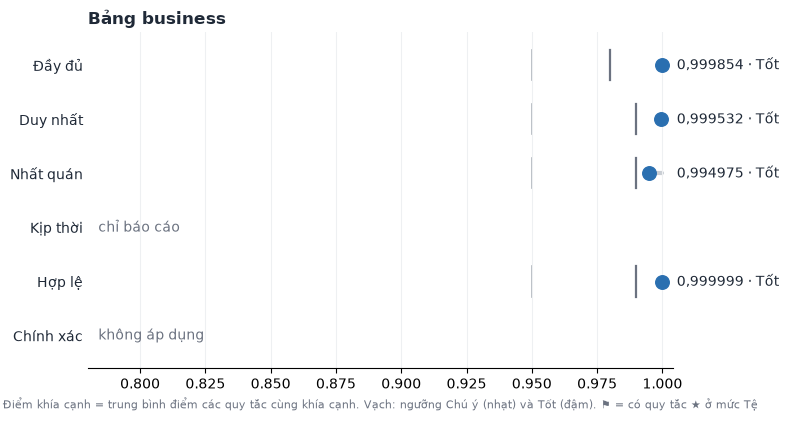

In [4]:
def show_table(t):
    sub = rules[rules.table == t]
    L = ["| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |", "|---|---|---|---|---:|---:|---:|---|"]
    for r in sub.itertuples():
        mark = "★ " if r.level == "star" else ""
        extra = f" (⚠ {int(r.n_flagged):,} ô cần kiểm chứng)" if r.n_flagged else ""
        L.append(f"| {mark}{r.rule_id} | {r.aspect} | {r.scope if isinstance(r.scope, str) else ''} | {r.desc}{extra} | "
                 f"{int(r.n_units):,} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} |")
    md(L)
    plot_table(aspects, t)

show_table("business")


### checkin

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |
|---|---|---|---|---:|---:|---:|---|
| ★ C5 | Đầy đủ | nội bảng | business_id ≠ null, mốc check-in không rỗng | 26,713,750 | 0 | 1,000000 | Tốt |
| C8 | Đầy đủ | liên bảng | độ phủ checkin/business (chỉ báo cáo) | 0 | 0 | - | Chỉ báo cáo |
| ★ V1 | Hợp lệ | nội bảng | business_id khớp chuỗi 22 ký tự | 13,356,875 | 0 | 1,000000 | Tốt |
| ★ V6 | Hợp lệ | nội bảng | mốc check-in đúng định dạng YYYY-MM-DD HH:MM:SS | 13,356,875 | 0 | 1,000000 | Tốt |
| ★ U1 | Duy nhất | nội bảng | cặp (business_id, checkin_time) không trùng (Tốt = 1) | 13,356,875 | 3,543 | 0,999735 | Chú ý |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business | 13,356,875 | 0 | 1,000000 | Tốt |
| ★ T3 | Kịp thời | nội bảng | mọi mốc check-in ≤ T_ref | 13,356,875 | 0 | 1,000000 | Tốt |

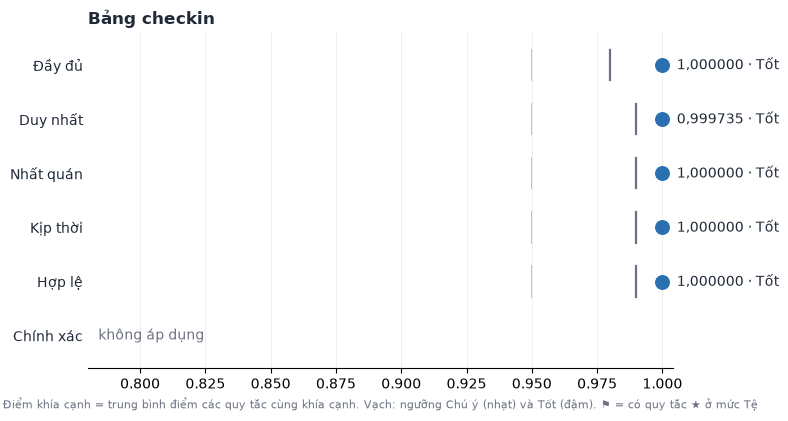

In [5]:
def show_table(t):
    sub = rules[rules.table == t]
    L = ["| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |", "|---|---|---|---|---:|---:|---:|---|"]
    for r in sub.itertuples():
        mark = "★ " if r.level == "star" else ""
        extra = f" (⚠ {int(r.n_flagged):,} ô cần kiểm chứng)" if r.n_flagged else ""
        L.append(f"| {mark}{r.rule_id} | {r.aspect} | {r.scope if isinstance(r.scope, str) else ''} | {r.desc}{extra} | "
                 f"{int(r.n_units):,} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} |")
    md(L)
    plot_table(aspects, t)

show_table("checkin")


### review

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |
|---|---|---|---|---:|---:|---:|---|
| ★ C3 | Đầy đủ | nội bảng | cả 9 trường ≠ null, text dài ≥ 1 | 62,912,520 | 0 | 1,000000 | Tốt |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 27,961,120 | 0 | 1,000000 | Tốt |
| ★ V1 | Hợp lệ | nội bảng | review_id, user_id, business_id khớp chuỗi 22 ký tự | 20,970,840 | 0 | 1,000000 | Tốt |
| ★ V3 | Hợp lệ | nội bảng | review.stars ∈ {1…5} (số nguyên) | 6,990,280 | 0 | 1,000000 | Tốt |
| ★ V4 | Hợp lệ | nội bảng | useful, funny, cool là số nguyên ≥ 0 | 20,970,840 | 7 | 1,000000 | Tốt |
| ★ V6 | Hợp lệ | nội bảng | date đúng định dạng YYYY-MM-DD HH:MM:SS | 6,990,280 | 0 | 1,000000 | Tốt |
| ★ U1 | Duy nhất | nội bảng | review_id không trùng (Tốt = 1) | 6,990,280 | 0 | 1,000000 | Tốt |
| U4 | Duy nhất | nội bảng | bộ (user_id, business_id, date) không lặp | 6,990,280 | 25 | 0,999996 | Tốt |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business; user_id ∈ user | 13,980,560 | 33 | 0,999998 | Tốt |
| S2 | Nhất quán | liên bảng | review.date ≥ user.yelping_since của chính người viết | 6,990,247 | 117 | 0,999983 | Tốt |
| ★ T1 | Kịp thời | nội bảng | review.date ∈ [T_start; T_ref] | 6,990,280 | 0 | 1,000000 | Tốt |

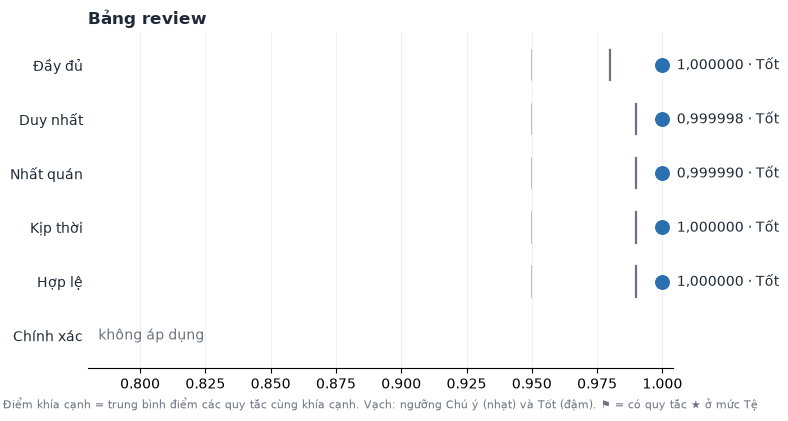

In [6]:
def show_table(t):
    sub = rules[rules.table == t]
    L = ["| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |", "|---|---|---|---|---:|---:|---:|---|"]
    for r in sub.itertuples():
        mark = "★ " if r.level == "star" else ""
        extra = f" (⚠ {int(r.n_flagged):,} ô cần kiểm chứng)" if r.n_flagged else ""
        L.append(f"| {mark}{r.rule_id} | {r.aspect} | {r.scope if isinstance(r.scope, str) else ''} | {r.desc}{extra} | "
                 f"{int(r.n_units):,} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} |")
    md(L)
    plot_table(aspects, t)

show_table("review")


### tip

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |
|---|---|---|---|---:|---:|---:|---|
| ★ C4 | Đầy đủ | nội bảng | user_id, business_id, text, date ≠ null | 3,635,660 | 0 | 1,000000 | Tốt |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 908,915 | 0 | 1,000000 | Tốt |
| ★ V1 | Hợp lệ | nội bảng | user_id, business_id khớp chuỗi 22 ký tự | 1,817,830 | 0 | 1,000000 | Tốt |
| ★ V4 | Hợp lệ | nội bảng | compliment_count là số nguyên ≥ 0 | 908,915 | 0 | 1,000000 | Tốt |
| ★ V6 | Hợp lệ | nội bảng | date đúng định dạng YYYY-MM-DD HH:MM:SS | 908,915 | 0 | 1,000000 | Tốt |
| U2 | Duy nhất | nội bảng | tip không có khóa riêng nên bộ (user_id, business_id, date, text) không lặp | 908,915 | 67 | 0,999926 | Tốt |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business; user_id ∈ user | 1,817,830 | 0 | 1,000000 | Tốt |
| S2 | Nhất quán | liên bảng | tip.date ≥ user.yelping_since của chính người viết | 908,915 | 0 | 1,000000 | Tốt |
| ★ T1 | Kịp thời | nội bảng | tip.date ∈ [T_start; T_ref] | 908,915 | 0 | 1,000000 | Tốt |

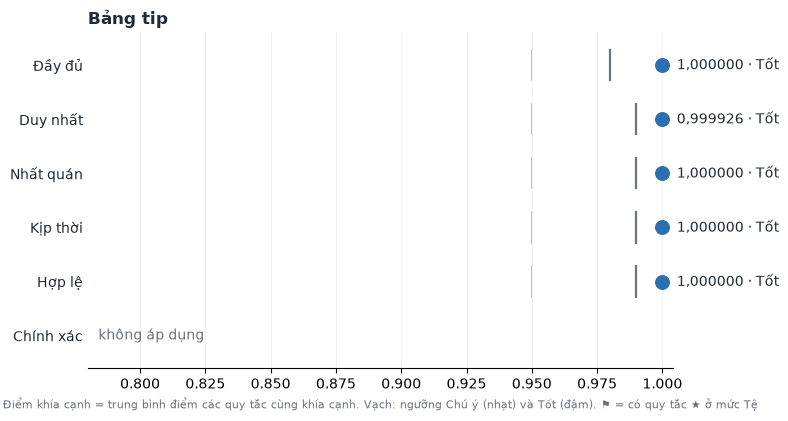

In [7]:
def show_table(t):
    sub = rules[rules.table == t]
    L = ["| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |", "|---|---|---|---|---:|---:|---:|---|"]
    for r in sub.itertuples():
        mark = "★ " if r.level == "star" else ""
        extra = f" (⚠ {int(r.n_flagged):,} ô cần kiểm chứng)" if r.n_flagged else ""
        L.append(f"| {mark}{r.rule_id} | {r.aspect} | {r.scope if isinstance(r.scope, str) else ''} | {r.desc}{extra} | "
                 f"{int(r.n_units):,} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} |")
    md(L)
    plot_table(aspects, t)

show_table("tip")


### user

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |
|---|---|---|---|---:|---:|---:|---|
| ★ C6 | Đầy đủ | nội bảng | user_id, yelping_since, review_count, average_stars ≠ null | 7,951,588 | 0 | 1,000000 | Tốt |
| C7 | Đầy đủ | nội bảng | tỷ lệ 'không có' của elite ('' ) và friends ('None' hoặc '[]') sau chuẩn hóa (chỉ báo cáo) | 3,975,794 | 2,775,250 | 0,301963 | Chỉ báo cáo |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 33,794,249 | 0 | 1,000000 | Tốt |
| ★ V1 | Hợp lệ | nội bảng | user_id khớp chuỗi 22 ký tự | 1,987,897 | 0 | 1,000000 | Tốt |
| ★ V4 | Hợp lệ | nội bảng | review_count, useful, funny, cool, fans, compliment_* là số nguyên ≥ 0 | 31,806,352 | 0 | 1,000000 | Tốt |
| ★ V6 | Hợp lệ | nội bảng | yelping_since đúng định dạng YYYY-MM-DD HH:MM:SS | 1,987,897 | 0 | 1,000000 | Tốt |
| ★ V7 | Hợp lệ | nội bảng | average_stars ∈ [1; 5] | 1,987,897 | 0 | 1,000000 | Tốt |
| V9 | Hợp lệ | nội bảng | elite là '' hoặc danh sách năm 4 chữ số (bắt lỗi dạng '20,20') | 1,987,897 | 39,929 | 0,979914 | Chú ý |
| V11 | Hợp lệ | nội bảng | friends là danh sách rỗng ('None', '[]') hoặc mọi phần tử là user_id đúng định dạng 22 ký tự (thêm max_rows để lấy mẫu nếu RAM hạn chế) | 1,987,897 | 0 | 1,000000 | Tốt |
| ★ U1 | Duy nhất | nội bảng | user_id không trùng (Tốt = 1) | 1,987,897 | 0 | 1,000000 | Tốt |
| S3 | Nhất quán | liên bảng | user.review_count ≥ số review của user đó có trong file review (file là tập con) | 1,987,897 | 17,665 | 0,991114 | Tốt |
| S4 | Nhất quán | nội bảng | elite: mỗi năm ≥ năm của yelping_since và ≤ 2022 | 90,979 | 0 | 1,000000 | Tốt |
| S8 | Nhất quán | liên bảng | average_stars lệch ≤ 0,5 so với trung bình review.stars của user trong file review | 1,987,897 | 742,635 | 0,626422 | Tệ |
| ★ T2 | Kịp thời | nội bảng | user.yelping_since ∈ [2004-07-01; T_ref] (cận dưới là thời điểm Yelp thành lập 07/2004, sớm hơn T_start của review; cần nhóm xác nhận) | 1,987,897 | 0 | 1,000000 | Tốt |

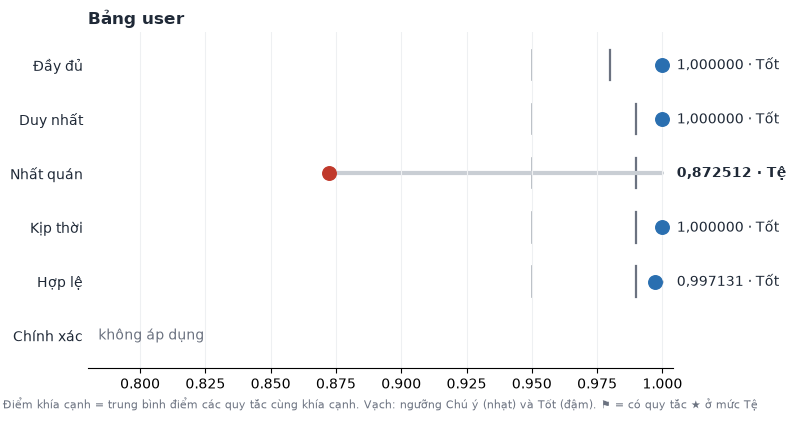

In [8]:
def show_table(t):
    sub = rules[rules.table == t]
    L = ["| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng |", "|---|---|---|---|---:|---:|---:|---|"]
    for r in sub.itertuples():
        mark = "★ " if r.level == "star" else ""
        extra = f" (⚠ {int(r.n_flagged):,} ô cần kiểm chứng)" if r.n_flagged else ""
        L.append(f"| {mark}{r.rule_id} | {r.aspect} | {r.scope if isinstance(r.scope, str) else ''} | {r.desc}{extra} | "
                 f"{int(r.n_units):,} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} |")
    md(L)
    plot_table(aspects, t)

show_table("user")


## 4. Việc cần xử lý

Quy tắc ở mức Chú ý/Tệ hoặc quy tắc ★ có vi phạm, kèm hướng xử lý đề xuất (dùng trực tiếp / gắn cờ / sửa-điền / loại).

In [9]:
need = rules[(rules.grade == "Tệ") | ((rules.level == "star") & (rules.n_violations > 0)) | (rules.grade == "Chú ý")]
order = need.grade.map({"Tệ": 0, "Chú ý": 2}).fillna(1)      # Tệ trước, rồi quy tắc ★ có vi phạm, rồi Chú ý
need = need.assign(_o=order).sort_values(["_o", "n_violations"], ascending=[True, False]).drop(columns="_o")
if len(need):
    L = ["| Bảng | Mã | Khía cạnh | Vi phạm | Điểm | Xếp hạng | Hướng xử lý | Giá trị vi phạm phổ biến |", "|---|---|---|---:|---:|---|---|---|"]
    for r in need.itertuples():
        top = r.top_values if isinstance(r.top_values, str) and r.top_values else "—"
        L.append(f"| {r.table} | {'★ ' if r.level == 'star' else ''}{r.rule_id} | {r.aspect} | {int(r.n_violations):,} | {vn(r.score)} | {r.grade} | {r.action} | {top} |")
    md(L)
else:
    md(["Không có quy tắc nào ở mức Chú ý/Tệ và không có quy tắc ★ nào bị vi phạm: dùng trực tiếp."])


| Bảng | Mã | Khía cạnh | Vi phạm | Điểm | Xếp hạng | Hướng xử lý | Giá trị vi phạm phổ biến |
|---|---|---|---:|---:|---|---|---|
| user | S8 | Nhất quán | 742,635 | 0,626422 | Tệ | Phải sửa / điền / loại trước khi dùng | average_stars: '3.0'×13481; '4.0'×10970; '3.67'×8970; '2.33'×4544; '3.5'×4093 |
| review | ★ S1 | Nhất quán | 33 | 0,999998 | Tốt | Xử lý mọi vi phạm (quy tắc ★) | user_id: 'lzpM_Vf2rKA4ivGtAIOH4w'×2; 'tquAg8GqbhN5k6Hkd23M0A'×1; '5iBVQ3OeK8lV4Z_4PXc1Xw'×1; 'u8cq-5zzD7dPSa3LR8rIMw'×1; '433BzxUeQAmRmK0g06UAfA'×1 |
| review | ★ V4 | Hợp lệ | 7 | 1,000000 | Tốt | Xử lý mọi vi phạm (quy tắc ★) | useful: '-1'×4 | funny: '-1'×2 | cool: '-1'×1 |
| business | ★ V2 | Hợp lệ | 1 | 0,999997 | Tốt | Xử lý mọi vi phạm (quy tắc ★) | longitude: '-73.2004570502'×1 |
| user | V9 | Hợp lệ | 39,929 | 0,979914 | Chú ý | Ghi nhận, gắn cờ hoặc xử lý nhẹ | elite: '2019,20,20,2021'×8058; '2018,2019,20,20,2021'×6701; '20,20,2021'×5061; '2017,2018,2019,20,20,2021'×4898; '2016,2017,2018,2019,20,20,...×3290 |
| checkin | ★ U1 | Duy nhất | 3,543 | 0,999735 | Chú ý | Xử lý mọi vi phạm (quy tắc ★) | — |
| business | S5a | Nhất quán | 1,791 | 0,988087 | Chú ý | Ghi nhận, gắn cờ hoặc xử lý nhẹ | city: 'St Petersburg'×387; 'St Louis'×357; 'King Of Prussia'×134; 'St. Charles'×104; "Land O' Lakes"×97 |

**Chỉ báo cáo (không xếp hạng):**

In [10]:
L = []
for r in rules[rules.level == "report"].itertuples():
    if r.n_units:
        L.append(f"- **{r.table} · {r.rule_id}** — {r.desc}: {int(r.n_violations):,}/{int(r.n_units):,} ô → tỷ lệ đạt {vn(r.score, 4)}.")
for m in metrics.itertuples():
    L.append(f"- **{m.table} · {m.rule_id}** — {m.metric}: {vn(m.value, 4)} ({m.numerator:,.0f}/{m.denominator:,.0f}); {m.note}.")
md(L or ["Không có."])


- **business · C7** — tỷ lệ thiếu của address, hours, attributes (chỉ báo cáo): 42,094/451,038 ô → tỷ lệ đạt 0,9067.
- **business · S6** — review_count so với số review trong file (chỉ báo cáo, chưa xếp hạng; kèm tổng và tỷ lệ): 67,362/150,346 ô → tỷ lệ đạt 0,5520.
- **business · T4** — tỷ lệ POI is_open = 1 có ít nhất một review/tip/check-in trong 24 tháng trước T_ref (chỉ báo cáo): 14,045/119,698 ô → tỷ lệ đạt 0,8827.
- **user · C7** — tỷ lệ 'không có' của elite ('' ) và friends ('None' hoặc '[]') sau chuẩn hóa (chỉ báo cáo): 2,775,250/3,975,794 ô → tỷ lệ đạt 0,3020.
- **business · S6** — tổng giá trị / tổng tham chiếu: 0,9650 (6,745,508/6,990,280); Σ review_count (mỗi business_id một lần) so với Σ review_n_by_business; chênh 244,772.
- **checkin · C8** — độ phủ: 0,8775 (131,930/150,346); business_id khác nhau nằm trong business.business_id.

**Ô lỗi mẫu** (tối đa 20 ô mỗi quy tắc, kèm khóa bản ghi để tra lại dữ liệu gốc):

In [11]:
cols = ["rule_id", "record", "cell", "value", "reference_name", "reference_value"]
if len(samples):
    for t, g in samples.groupby("table", sort=False):
        display(HTML(f"<details><summary><b>{t}</b>: {len(g)} ô lỗi mẫu (bấm để mở)</summary>"
                     + g[cols].to_html(index=False, max_rows=None, na_rep="") + "</details>"))
else:
    md(["Không có ô lỗi."])


rule_id,record,cell,value,reference_name,reference_value
C2,business_id='6cPVGUOVlHa6TwlgU08IXQ'; name='Dr.Green',postal_code,'',,
C2,"business_id='siwG4ZM7RjUDO52DI84m3w'; name=""Ray's Vegan Soul""",postal_code,'',,
C2,business_id='m84BCUA6aDi03mRyufHYBw'; name='Harlow Pest & Sanitation Control',postal_code,'',,
C2,business_id='VEdEuOfDGhgRWO-PipfB7w'; name='Fill A Seat Philadelphia',postal_code,'',,
C2,business_id='--sXnWH9Xm6_NvIjyuA99w'; name='Philadelphia',postal_code,'',,
C2,business_id='4vvu78FMlZyQwZf0bBUkLQ'; name='Indy 500 Parade',postal_code,'',,
C2,business_id='UZ7mpi6qcsS0FqsH-cyfnA'; name='Krewe of Choctaw',postal_code,'',,
C2,business_id='9KSHmObBPY0AF27uHtGcLQ'; name='Laurel Hawkswell - Caricature Artist',postal_code,'',,
C2,business_id='iScjM-BsvC9VTeOSCpU7aw'; name='Altitud',postal_code,'',,
C2,business_id='mObvxzRcbFmi6fybvx1kvw'; name='Scribble Food Truck',postal_code,'',,


rule_id,record,cell,value,reference_name,reference_value
U1,business_id='-0TffRSXXIlBYVbb5AwfTg'; checkin_time=2015-02-22 19:25:58,"(business_id, checkin_time)","""business_id='-0TffRSXXIlBYVbb5AwfTg'; checkin_time=2015-02-22 19:25:58""",,
U1,business_id='-0Ym1Wg3bXd_TDz8JtvOQg'; checkin_time=2018-11-25 21:25:27,"(business_id, checkin_time)","""business_id='-0Ym1Wg3bXd_TDz8JtvOQg'; checkin_time=2018-11-25 21:25:27""",,
U1,business_id='-1B9pP_CrRBJYPICE5WbRA'; checkin_time=2015-04-24 22:18:54,"(business_id, checkin_time)","""business_id='-1B9pP_CrRBJYPICE5WbRA'; checkin_time=2015-04-24 22:18:54""",,
U1,business_id='-1B9pP_CrRBJYPICE5WbRA'; checkin_time=2016-02-19 00:49:11,"(business_id, checkin_time)","""business_id='-1B9pP_CrRBJYPICE5WbRA'; checkin_time=2016-02-19 00:49:11""",,
U1,business_id='-2YZIUArmrIMVVBi8CT47w'; checkin_time=2017-03-12 01:19:31,"(business_id, checkin_time)","""business_id='-2YZIUArmrIMVVBi8CT47w'; checkin_time=2017-03-12 01:19:31""",,
U1,business_id='-3-6BB10tIWNKGEF0Es2BA'; checkin_time=2021-03-06 03:29:29,"(business_id, checkin_time)","""business_id='-3-6BB10tIWNKGEF0Es2BA'; checkin_time=2021-03-06 03:29:29""",,
U1,business_id='-3e3CP3FFc-rvJj_-_airw'; checkin_time=2013-08-18 23:09:56,"(business_id, checkin_time)","""business_id='-3e3CP3FFc-rvJj_-_airw'; checkin_time=2013-08-18 23:09:56""",,
U1,business_id='-5Rah4ZvWsDu4oilUZxhtw'; checkin_time=2012-07-16 00:13:14,"(business_id, checkin_time)","""business_id='-5Rah4ZvWsDu4oilUZxhtw'; checkin_time=2012-07-16 00:13:14""",,
U1,business_id='-6kIZWnXPuDC6JiQJ-A1fg'; checkin_time=2018-05-18 12:30:43,"(business_id, checkin_time)","""business_id='-6kIZWnXPuDC6JiQJ-A1fg'; checkin_time=2018-05-18 12:30:43""",,
U1,business_id='-6osFx4NgFRHJ5NXqpHV6g'; checkin_time=2015-02-07 23:54:05,"(business_id, checkin_time)","""business_id='-6osFx4NgFRHJ5NXqpHV6g'; checkin_time=2015-02-07 23:54:05""",,


rule_id,record,cell,value,reference_name,reference_value
V4,review_id='plhadSWfXZFKRAhEztb6Dw'; business_id='SJQePJL1bkeEk-6gp-6eeA',useful,-1,,
V4,review_id='gk_9N_c-7oEgzrXVDaR8-g'; business_id='SJQePJL1bkeEk-6gp-6eeA',useful,-1,,
V4,review_id='iYS4pfUCUPT_TEmW6BOnrA'; business_id='SJQePJL1bkeEk-6gp-6eeA',useful,-1,,
V4,review_id='JcWLycg0Hdsz6LBNAqS37A'; business_id='E3Qk7xTznkT0SABL2ltpHA',useful,-1,,
V4,review_id='JcWLycg0Hdsz6LBNAqS37A'; business_id='E3Qk7xTznkT0SABL2ltpHA',funny,-1,,
V4,review_id='7tlF2NEDiFqMRjKBgTPJ3g'; business_id='qjstXewt23oCZnf86CsHXg',funny,-1,,
V4,review_id='JcWLycg0Hdsz6LBNAqS37A'; business_id='E3Qk7xTznkT0SABL2ltpHA',cool,-1,,
U4,review_id='DXk7XQ4drjxpoR1hXQPPxA'; business_id='XHEoP7Otn8RMH9r8WTJnOA',"(user_id, business_id, date)","""user_id='H_TgEZddpky6VOB9Xmzbvg'; business_id='XHEoP7Otn8RMH9r8WTJnOA'; date...",,
U4,review_id='FmEWJou0hHUiEGCMmThz5Q'; business_id='zwXT4m9svdg-xh2cKjEp-Q',"(user_id, business_id, date)","""user_id='FHIZVv4yXhSAULPkxqsHxQ'; business_id='zwXT4m9svdg-xh2cKjEp-Q'; date...",,
U4,review_id='d-2yAAWXkT9iMUcIly1zVQ'; business_id='zwXT4m9svdg-xh2cKjEp-Q',"(user_id, business_id, date)","""user_id='FHIZVv4yXhSAULPkxqsHxQ'; business_id='zwXT4m9svdg-xh2cKjEp-Q'; date...",,


rule_id,record,cell,value,reference_name,reference_value
U2,user_id='00Cz_vdInMHpTRjqbWjK5Q'; business_id='ncacMQ9n_dSM1cR3c1vTQw',"(user_id, business_id, date, text)","""user_id='00Cz_vdInMHpTRjqbWjK5Q'; business_id='ncacMQ9n_dSM1cR3c1vTQw'; date...",,
U2,user_id='47zMh_WgunwRDf7Cx2WyYw'; business_id='J8vz_zwZaxzA585lV_k_vA',"(user_id, business_id, date, text)","""user_id='47zMh_WgunwRDf7Cx2WyYw'; business_id='J8vz_zwZaxzA585lV_k_vA'; date...",,
U2,user_id='WQ8shYm0ghNDz97BuHI1fA'; business_id='Sv1MEZP-mMfp8SmE0hwYEA',"(user_id, business_id, date, text)","""user_id='WQ8shYm0ghNDz97BuHI1fA'; business_id='Sv1MEZP-mMfp8SmE0hwYEA'; date...",,
U2,user_id='hGxVvXVg7IK4J2aTiGMSIQ'; business_id='5RsVAkDnMrcSbErS6P1eew',"(user_id, business_id, date, text)","""user_id='hGxVvXVg7IK4J2aTiGMSIQ'; business_id='5RsVAkDnMrcSbErS6P1eew'; date...",,
U2,user_id='1gDoko0TrN0lnQlMC2JtXw'; business_id='06PmqoU3uY5Vb-BEaMPVfw',"(user_id, business_id, date, text)",'user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'; ...,,
U2,user_id='Tf63LdfubjlFm974OrdTXg'; business_id='CyiN_owscPJNvlwul0XJPg',"(user_id, business_id, date, text)","""user_id='Tf63LdfubjlFm974OrdTXg'; business_id='CyiN_owscPJNvlwul0XJPg'; date...",,
U2,user_id='3nBDXQT81w91zv8NPke8Mw'; business_id='2JEzWTF9tazzjyzCTsOWQw',"(user_id, business_id, date, text)","""user_id='3nBDXQT81w91zv8NPke8Mw'; business_id='2JEzWTF9tazzjyzCTsOWQw'; date...",,
U2,user_id='1gDoko0TrN0lnQlMC2JtXw'; business_id='06PmqoU3uY5Vb-BEaMPVfw',"(user_id, business_id, date, text)",'user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'; ...,,
U2,user_id='q46P4WXcdOeIx0yE5keY9Q'; business_id='pWuoHHu0LuVrD0HjadDygg',"(user_id, business_id, date, text)","""user_id='q46P4WXcdOeIx0yE5keY9Q'; business_id='pWuoHHu0LuVrD0HjadDygg'; date...",,
U2,user_id='1gDoko0TrN0lnQlMC2JtXw'; business_id='06PmqoU3uY5Vb-BEaMPVfw',"(user_id, business_id, date, text)",'user_id=\'1gDoko0TrN0lnQlMC2JtXw\'; business_id=\'06PmqoU3uY5Vb-BEaMPVfw\'; ...,,


rule_id,record,cell,value,reference_name,reference_value
C7,user_id='hA5lMy-EnncsH4JoR-hFGQ',elite,'',,
C7,user_id='cxuxXkcihfCbqt5Byrup8Q',elite,'',,
C7,user_id='E9kcWJdJUHuTKfQurPljwA',elite,'',,
C7,user_id='lO1iq-f75hnPNZkTy3Zerg',elite,'',,
C7,user_id='AUi8MPWJ0mLkMfwbui27lg',elite,'',,
C7,user_id='iYzhPPqnrjJkg1JHZyMhzA',elite,'',,
C7,user_id='vVukUtqoLF5BvH_VtQFNoA',elite,'',,
C7,user_id='_crIokUeTCHVK_JVOy-0qQ',elite,'',,
C7,user_id='1McG5Rn_UDkmlkZOrsdptg',elite,'',,
C7,user_id='fJZO_skqpnhk1kvomI4dmA',elite,'',,


## 5. Giới hạn và tham số cần xác nhận

- **Mốc thời gian**: T_ref = 2022-01-19 (ngày xuất snapshot), khung Kịp thời bắt đầu 2005-02-16 theo báo cáo (nguồn cần xác nhận); riêng T2 dùng 01/07/2004 (Yelp thành lập 07/2004).
- **Ngưỡng** lấy từ Bảng A.1 của báo cáo CLDL; nhóm có thể đổi trong `CONFIG_YAML` (mục `thresholds`) trong `danh_gia_cldl.py`.
- **Đơn vị đo là ô**: khóa ghép (U2–U4) tính một ô tổ hợp; ô nhiều giá trị (vd. `friends`) sai nếu có một phần tử sai; vi phạm trùng lặp đếm số bản sao thừa.
- **Quy tắc đối chiếu** (S6–S8, giá trị tính từ bảng khác) chỉ nói *hai nguồn có khớp nhau không*, chưa chứng minh nguồn nào đúng; xem ô "cần kiểm chứng" nếu có.
- Điểm dồn sát 1 nên biểu đồ không bắt đầu từ 0; đọc cùng bảng điểm và số ô vi phạm.


## 6. Kiểm tra code

In [12]:
st = meta.get("selftest") or []
md([f"**{sum(c['ok'] for c in st)}/{len(st)} kiểm tra đạt** (dữ liệu giả có tiêm lỗi biết trước, chạy cùng bộ quy tắc):", ""]
   + [f"- {'✅' if c['ok'] else '❌'} {c['name']}" + ("" if c["ok"] else f" - {c['detail']}") for c in st] if st else ["Chưa chạy tự kiểm (--no-selftest)."])


**16/16 kiểm tra đạt** (dữ liệu giả có tiêm lỗi biết trước, chạy cùng bộ quy tắc):

- ✅ Số ô vi phạm của MỌI quy tắc khớp số lỗi đã tiêm
- ✅ Không dương tính giả (quy tắc không tiêm lỗi thì phải bằng 0)
- ✅ Mọi quy tắc trong cấu hình đều chạy được
- ✅ Chỉ số tham chiếu C8 (độ phủ) và S6 (tổng review_count) khớp tính tay
- ✅ Quy tắc chỉ báo cáo (T4) không xếp hạng
- ✅ Duy nhất chỉ đếm bản dư thừa (6 dòng thuộc khóa trùng, 3 lỗi)
- ✅ Điểm quy tắc = 1 − False/(True+False); ô N/A không được xét
- ✅ Điểm khía cạnh = trung bình điểm các quy tắc xếp hạng; cờ ⚑ đúng khi có quy tắc ★ ở mức Tệ
- ✅ Khía cạnh không áp dụng đều có lý do (Chính xác ở cả 5 bảng)
- ✅ Đầy đủ/Hợp lệ: ô thiếu hoặc rỗng là N/A ở regex; sai kiểu chỉ bị dtype bắt, range bỏ qua ô không phải số
- ✅ Kịp thời: gồm hết ngày T_ref, cận dưới riêng của T2
- ✅ Duy nhất: khóa ghép là một ô; lần đầu True, bản sau False, khóa thiếu N/A
- ✅ Nhất quán: khóa ngoại (mồ côi False) và ngày ≥ ngày tra cứu
- ✅ Nhất quán: đối chiếu số liệu liên bảng (at_least / two_sided)
- ✅ Quy tắc ★ ở mức Tệ gắn cờ ⚑ dù điểm trung bình khía cạnh vẫn Tốt
- ✅ Mỗi loại kiểm tra đều có mô tả True/False/N/A và lý do